# Bitcoin forecasting with XGBoost 
Chronological Train 80% / Test 20%; no validation or early stopping; predefined parameter candidates ranked using Train price RMSE only. Seven direct models fitted once on Train, with frozen trees throughout rolling-origin Test and future forecasts. USD RMSE and MAPE only. Horizons are calendar days; one month = 30 days.

Run top to bottom using **Python 3.12 (vs_nine TensorFlow)**. Outputs go to `PROJECT_2026/OUTPUT/outputs_xgb/{tables,figures,models,summaries}`. Lag features contain Price-derived returns only. Historical Test forecasts and future forecasts are separate.

**Current experiment:** Top 5 parameter sets are displayed before Test, with an explicit Best on Train table. Existing Test/future dates were inspected previously, so the rerun is retrospective. Search reports are exported under `OUTPUT/XGBOOST_TRAIN_SEARCH/`.


### XGBoost results navigation — current Train-only parameter search

- [Top 5 candidates and Best on Train](#xgb-top5-train): **section 6.1**, before final fitting and Test.
- [Original archived Future evaluation](#task1-future-metrics): original saved forecasts retained.
- [Revised Future evaluation](#xgb-revised-future): selected models from the current run, retrospective.
- [Task 2 — current Test RMSE/MAPE](#task2-test-metrics): rank-1 models fixed during Test.

`Candidate ID` is the parameter-combination identifier; `rank` orders Train RMSE. Search exports: `OUTPUT/XGBOOST_TRAIN_SEARCH/BTC/tables/`.


## Step 1  Environment and fixed configuration

In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import hashlib
import xgboost
from xgboost import XGBRegressor
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
from IPython.display import display, Markdown, HTML

DATA_PATH = 'Bitcoin_Historical_Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
MAX_H = 30
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
LOOKBACK = 40
RANDOM_STATE = 0
XGB_PARAMS = dict(objective='reg:squarederror', n_estimators=100,
    learning_rate=0.3, max_depth=6, min_child_weight=1, gamma=0,
    subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0, reg_alpha=0.0,
    tree_method='hist', random_state=RANDOM_STATE)
ALPHA = 0.05
assert max(HORIZONS) == MAX_H
assert max(DAILY_FORECAST_WINDOWS) <= MAX_H
search_dirs = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((base for base in search_dirs
    if (base/'BTC_TEST').is_dir() and (base/'CSV').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch JupyterLab inside PROJECT_2026 or BTC_TEST.')
data_file = Path(DATA_PATH)
if not data_file.is_file():
    paths = [base/rel for base in search_dirs for rel in
        ['Bitcoin_Historical_Data.csv','BTC_TEST/Bitcoin_Historical_Data.csv',
         'CSV/Bitcoin Historical Data.csv','CSV/Bitcoin_Historical_Data.csv']]
    data_file = next((path for path in paths if path.is_file()), data_file)
if not data_file.is_file(): raise FileNotFoundError('Set DATA_PATH to the Bitcoin CSV.')
DATA_PATH = str(data_file.resolve())
OUTPUT_DIR = PROJECT_ROOT/'OUTPUT'/'outputs_xgb'
TABLE_DIR, FIGURE_DIR, MODEL_DIR = (OUTPUT_DIR/name for name in ['tables','figures','models'])
SUMMARY_DIR = OUTPUT_DIR/'summaries'
for directory in [TABLE_DIR,FIGURE_DIR,MODEL_DIR,SUMMARY_DIR]: directory.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in
    ['pandas','numpy','matplotlib','xgboost','statsmodels','scipy']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable)
display(versions)
print('Data:',DATA_PATH,'\nOutputs:',OUTPUT_DIR)
versions.to_csv(TABLE_DIR/'library_versions.csv',index=False)
def save_table(frame,name): frame.to_csv(TABLE_DIR/name,index=False,encoding='utf-8-sig')
def save_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIGURE_DIR/name,dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        +frame.to_html(index=False,float_format=lambda x:f'{x:,.2f}')+'</div>'))


# Compare tree state, not prediction caches.
def model_digest(model):
    return hashlib.sha256(model.get_booster().save_raw(raw_format='json')).hexdigest()
(SUMMARY_DIR/'fixed_parameters.json').write_text(json.dumps(XGB_PARAMS,indent=2),encoding='utf-8')
# Separate PI models; original point-forecast settings are unchanged.
XGB_PI_ALPHA = 0.05
XGB_PI_QUANTILES = [XGB_PI_ALPHA/2, 1-XGB_PI_ALPHA/2]


# Candidate grid fixed before any Test/future scoring; rank by Train price RMSE.
XGB_SEARCH_CONFIG = dict(n_estimators=[50, 100, 200], learning_rate=[0.1, 0.3],
    max_depth=[3, 6, 8], top_n=5, ranking='Train RMSE in original price units',
    validation=False, cross_validation=False, run_id='xgb_train_rmse_top5_v1')


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,xgboost,3.4.1
4,statsmodels,0.15.0
5,scipy,1.18.1


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\Bitcoin Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_xgb


## Step 2  Data preparation

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date','Price','Open','High','Low','Vol.','Change %']
assert set(required).issubset(raw.columns)
assert not raw[required].isna().any().any()
df = raw[required].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
assert not df['Date'].duplicated().any(), 'Duplicate dates'
df = df.sort_values('Date')
for column in ['Price','Open','High','Low']:
    df[column] = pd.to_numeric(df[column].str.replace(',', '', regex=False), errors='raise').astype(float)
vol = df['Vol.'].str.strip().str.upper().str.replace(',', '', regex=False)
parts = vol.str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unknown volume format'
df['Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol.str.endswith('B')].copy()
save_table(b_rows, 'volume_B_rows.csv')
print('Volume B rows retained:', len(b_rows))
df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
df = df.drop(columns='Vol.').set_index('Date').asfreq('D')
assert df.index.is_monotonic_increasing and df.index.is_unique
assert not df.isna().any().any(), 'Missing data or calendar gaps'
assert np.isfinite(df.to_numpy()).all() and (df['Price'] > 0).all()
assert len(df) == 1897
assert df.index[0] == pd.Timestamp('2021-07-01') and df.index[-1] == pd.Timestamp('2026-09-09')
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and log_ret.iloc[1:].notna().all()
display(df.head())

Volume B rows retained: 16


,Price,Open,High,Low,Change %,Volume
Date,,,,,,
2021-07-01,33543.6,35030.7,35032.7,32839.2,-0.0423,27410.0
2021-07-02,33813.4,33542.2,33925.9,32734.6,0.0080,78930.0
2021-07-03,34742.8,33814.2,34909.8,33363.3,0.0275,55690.0
2021-07-04,35298.2,34742.8,35957.6,34740.1,0.0160,56130.0
2021-07-05,33687.8,35297.0,35300.5,33164.1,-0.0456,88360.0


## Step 3 Exploratory plots (descriptive only)

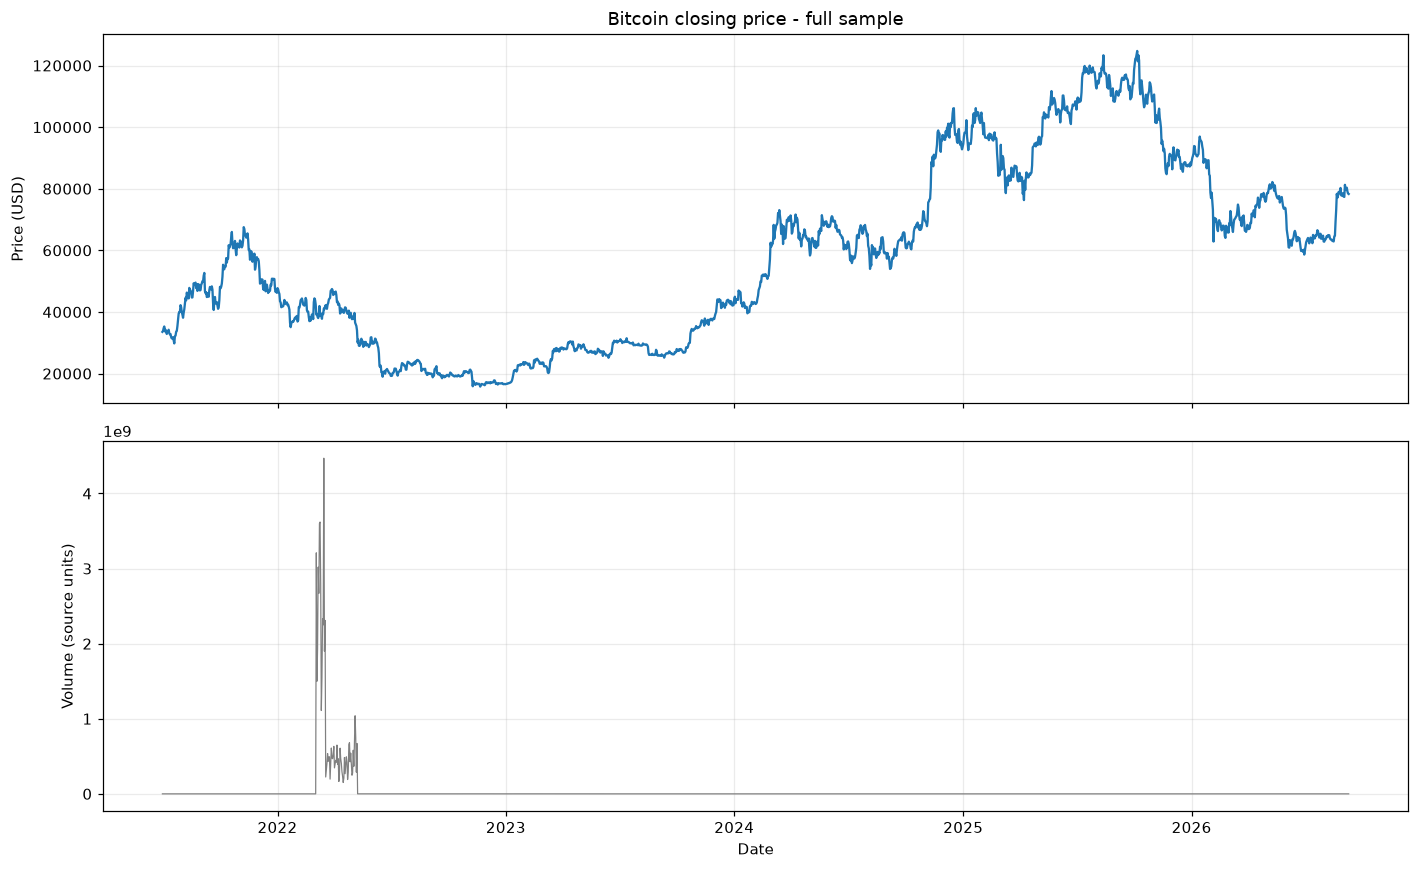

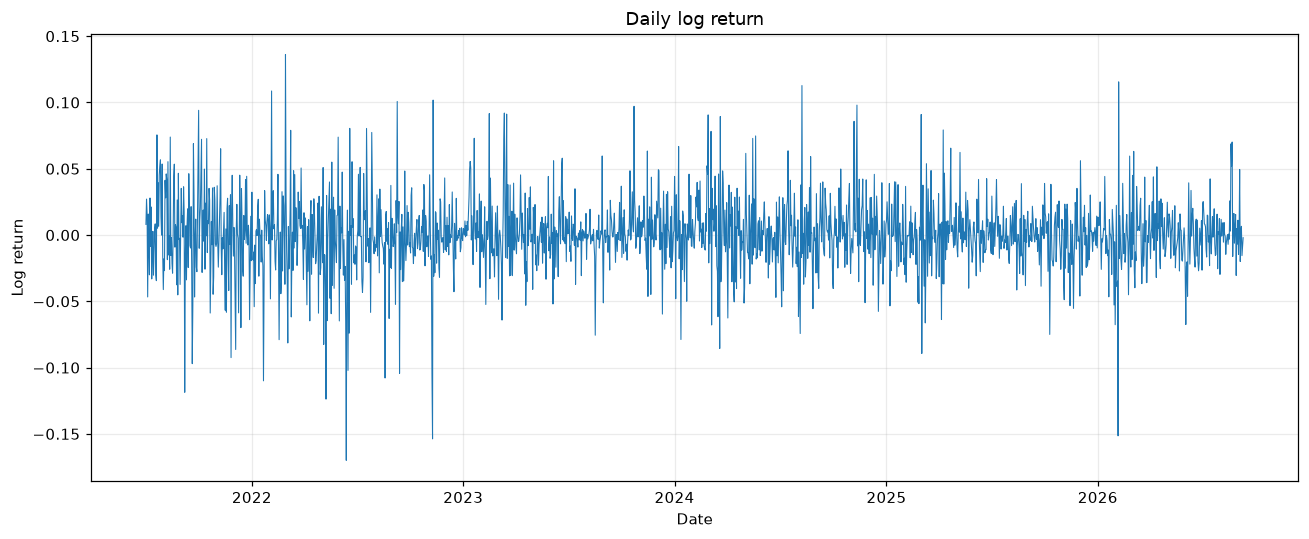

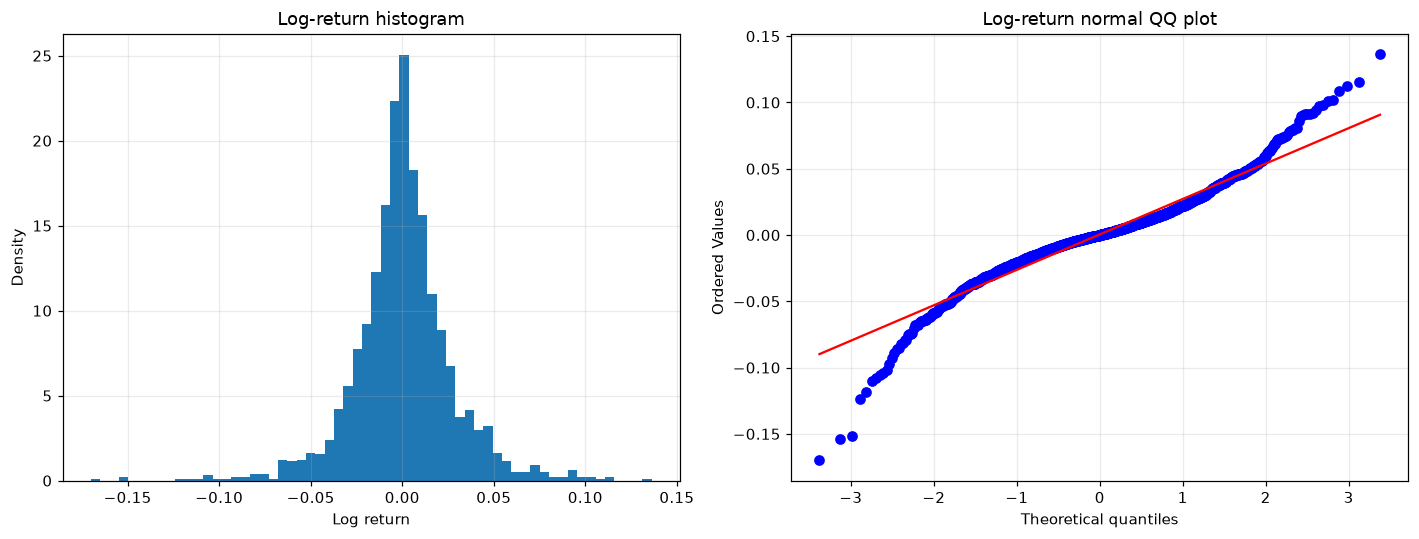

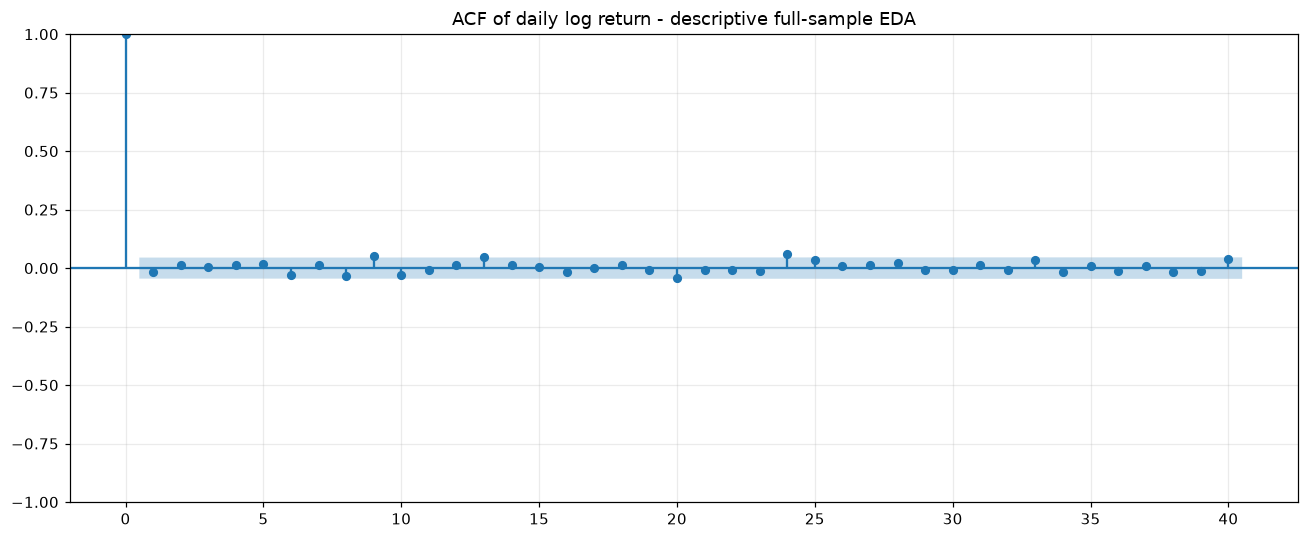

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df.index, df['Price'])
axes[0].set(title='Bitcoin closing price - full sample', ylabel='Price (USD)')
axes[1].plot(df.index, df['Volume'], color='gray', linewidth=0.8)
axes[1].set(ylabel='Volume (source units)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')
fig, ax = plt.subplots()
ax.plot(log_ret, linewidth=0.7)
ax.set(title='Daily log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '02_log_return.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_ret.dropna(), bins=60, density=True)
axes[0].set(title='Log-return histogram', xlabel='Log return', ylabel='Density')
stats.probplot(log_ret.dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(), lags=40, ax=ax)
ax.set_title('ACF of daily log return - descriptive full-sample EDA')
save_figure(fig, '04_acf_log_return.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [4]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,USD,USD,USD
Start,2021-07-01,2021-07-01,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1897,1517,380
Mean,57629.849499,51303.65056,82884.701579
SD,29376.877181,28293.431673,17763.14492
Min,15776.2,15776.2,58630.8
Q1,29798.5,27603.3,67206.375
Median,57534.6,43188.2,78230.25
Q3,78333.9,66798.7,92535.0


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1896,1516,380
Mean,0.000447,0.000784,-0.000897
SD,0.027453,0.028476,0.022908
Min,-0.169947,-0.169947,-0.151458
Q1,-0.01253,-0.012301,-0.014073
Median,-0.000094,-0.000025,-0.000511
Q3,0.013332,0.014076,0.011167


## Step 4 Chronological split BEFORE feature construction

,split,start_date,end_date,n_days,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-08-25,1517,15776.2,123323.4,51303.650560,1516,0.000784,0.028476
1,Test,2025-08-26,2026-09-09,380,58630.8,124725.1,82884.701579,380,-0.000897,0.022908


Return SD above uses ddof=1; No scaler is fitted in this notebook.


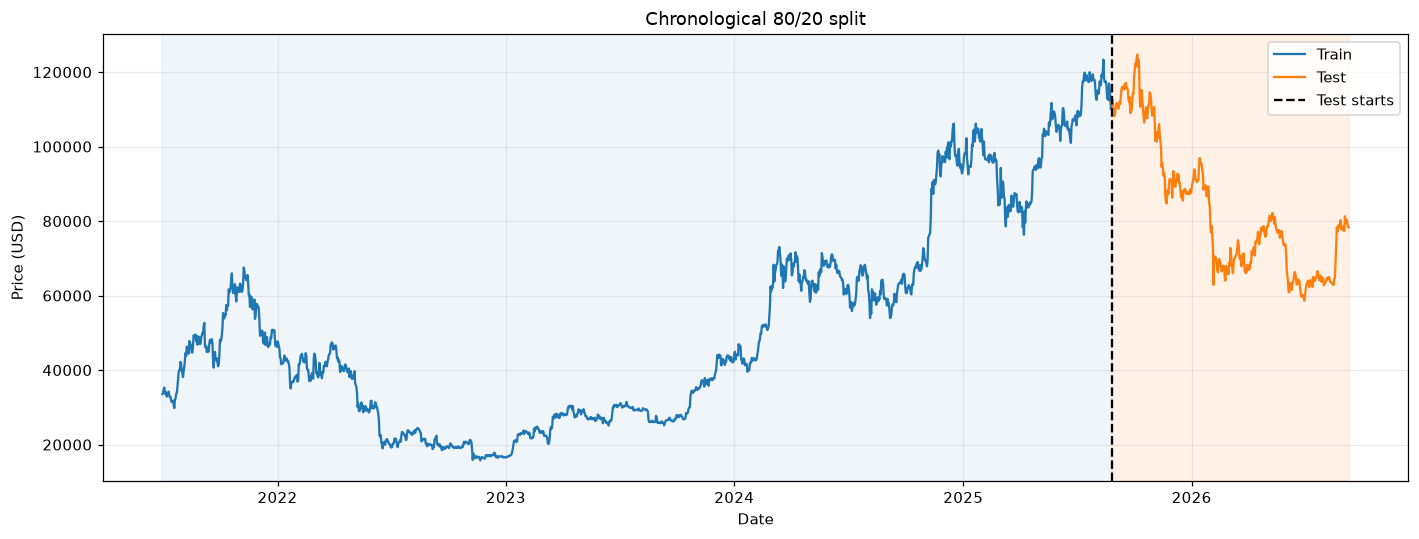

In [5]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert (n_train, n_test, TRAIN_END_IDX) == (1517, 380, 1516)
assert df.index[TRAIN_END_IDX] == pd.Timestamp('2025-08-25')
assert df.index[n_train] == pd.Timestamp('2025-08-26')
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_days=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; No scaler is fitted in this notebook.')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')

## Step 5 Predetermined target transformation
Use cumulative log return `y(t,h) = log_price[t+h] - log_price[t]` rather than price levels. This choice is fixed by the specification, not selected using Test prices. No feature or target scaling is needed.

Trees give piecewise constant responses; boosted predictions sum leaf contributions and can exceed the observed target range. They still do not extrapolate a time trend as a linear model does. Anchoring `forecast = price_origin * exp(predicted_return)` allows reconstructed USD prices above historical training prices without learning price-level extrapolation. This does not eliminate regime changes or guarantee accuracy.

In [6]:
train_log = log_price.iloc[:n_train].copy()
train_returns = log_ret.iloc[:n_train].copy()
assert train_log.index[-1] == df.index[TRAIN_END_IDX]
print('Target: cumulative log return; no learned transformation or scaling.')

Target: cumulative log return; no learned transformation or scaling.


## Step 6 Training-only features and direct targets
`lag_1 = log_ret[t]`, ..., `lag_60 = log_ret[t-59]`. Each origin uses only its own history. Horizon-specific training targets must end within Train. Test input construction occurs only in Step 8; observed Test history becomes available as origins advance.

In [7]:
feature_names = [f'lag_{j}' for j in range(1,LOOKBACK+1)]
training, provenance_rows = {}, []
for h in HORIZONS:
    origins = np.arange(LOOKBACK,TRAIN_END_IDX-h+1)
    input_idx = origins[:,None]-np.arange(LOOKBACK)[None,:]
    target_idx = origins+h
    assert input_idx.min()>=1 and input_idx.max()<=TRAIN_END_IDX
    assert (input_idx<=origins[:,None]).all() and target_idx.max()<=TRAIN_END_IDX
    X = pd.DataFrame(train_returns.to_numpy()[input_idx],columns=feature_names,index=df.index[origins])
    y = train_log.iloc[target_idx].to_numpy()-train_log.iloc[origins].to_numpy()
    assert len(origins)==n_train-LOOKBACK-h and X.shape==(len(origins),LOOKBACK)
    assert np.isfinite(X.to_numpy()).all() and np.isfinite(y).all()
    training[h]=dict(origins=origins,input_idx=input_idx,target_idx=target_idx,X=X,y=y)
    provenance_rows.append(dict(h=h,n_train=len(origins),feature_min_idx=int(input_idx.min()),
        feature_max_idx=int(input_idx.max()),target_max_idx=int(target_idx.max()),
        target_max_date=df.index[target_idx.max()]))
provenance = pd.DataFrame(provenance_rows)
save_table(provenance,'training_provenance.csv')
display(provenance)

,h,n_train,feature_min_idx,feature_max_idx,target_max_idx,target_max_date
0,1,1476,1,1515,1516,2025-08-25
1,3,1474,1,1513,1516,2025-08-25
2,5,1472,1,1511,1516,2025-08-25
3,7,1470,1,1509,1516,2025-08-25
4,14,1463,1,1502,1516,2025-08-25
5,21,1456,1,1495,1516,2025-08-25
6,30,1447,1,1486,1516,2025-08-25


<a id="xgb-top5-train"></a>

### 6.1 — XGBoost Top 5 parameter sets before Test (Train RMSE only)

Keep the original chronological Train/Test 80/20 split, no validation/CV and the original lookback/calendar. Rank 18 predefined combinations of `n_estimators` (50/100/200), `learning_rate` (0.1/0.3) and `max_depth` (3/6/8) separately at each horizon, using **Train RMSE in USD**. Other parameters are fixed and displayed below. Search all 30 daily-path horizons before any Test forecasting.

Show five **distinct parameter sets per requested horizon** (1/3/5/7/14/21/30). `rank=1`, `Best_on_Train=True` and `BEST ON TRAIN - SELECTED` identify the selected model; a separate best-model table follows. Candidate ID is a fixed trial identifier, not the rank. MAPE is descriptive, never the selection criterion. Numerical fitting checks apply; BTC also retains its existing Train-loss-curve eligibility gate. The `validation_0` API label below refers to the identical fitting Train data, not a validation partition.

Train-fit ranking does not establish future accuracy. Existing Test and supplied future-actual periods have already been inspected; this rerun is retrospective, not a new untouched holdout. No Test/future value enters candidate ranking. Existing quantile PI models retain their separate fixed Train-only specification; only the point-forecast model is selected by this search.


In [8]:
# Train-only candidate search: no Test targets, Test scores or future actuals.
from itertools import product
xgb_search_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'CSV').is_dir() and (base / 'ACTUAL_FOR_PREDICT').is_dir())
xgb_search_output = xgb_search_root / 'OUTPUT' / 'XGBOOST_TRAIN_SEARCH' / 'BTC'
xgb_search_table_dir = xgb_search_output / 'tables'
xgb_search_summary_dir = xgb_search_output / 'summaries'
for xgb_directory in [xgb_search_table_dir, xgb_search_summary_dir]:
    xgb_directory.mkdir(parents=True, exist_ok=True)
xgb_reference_parameters = dict(XGB_PARAMS)
# Fixed CPU budget and seed apply to every candidate and selected point model.
xgb_reference_parameters['n_jobs'] = 2
assert xgb_reference_parameters['objective'] == 'reg:squarederror'
xgb_search_prices = df['Price'].to_numpy(dtype=float)
xgb_search_log_price = np.asarray(log_price, dtype=float)
xgb_search_returns = log_ret.to_numpy(dtype=float)
xgb_search_rows = []
xgb_search_windows = {}
xgb_search_grid = list(product(XGB_SEARCH_CONFIG['n_estimators'],
    XGB_SEARCH_CONFIG['learning_rate'], XGB_SEARCH_CONFIG['max_depth']))
assert len(xgb_search_grid) >= XGB_SEARCH_CONFIG['top_n']
for xgb_h in range(1, max(HORIZONS)+1):
    xgb_origins = np.arange(LOOKBACK, n_train-xgb_h)
    xgb_indices = xgb_origins[:, None]-np.arange(LOOKBACK)[None, :]
    xgb_targets = xgb_origins+xgb_h
    assert xgb_targets.max() == n_train-1 and xgb_indices.min() >= 1
    assert (xgb_indices <= xgb_origins[:, None]).all()
    assert len(xgb_origins) == n_train-LOOKBACK-xgb_h
    xgb_X = xgb_search_returns[xgb_indices]
    if True:
        xgb_X = pd.DataFrame(xgb_X, columns=feature_names)
    xgb_y = xgb_search_log_price[xgb_targets]-xgb_search_log_price[xgb_origins]
    assert np.isfinite(np.asarray(xgb_X)).all() and np.isfinite(xgb_y).all()
    xgb_search_windows[xgb_h] = dict(origins=xgb_origins, targets=xgb_targets)
    for xgb_id, (xgb_rounds, xgb_rate, xgb_depth) in enumerate(xgb_search_grid, start=1):
        xgb_params = dict(xgb_reference_parameters, n_estimators=xgb_rounds,
            learning_rate=xgb_rate, max_depth=xgb_depth)
        xgb_candidate = XGBRegressor(**xgb_params)
        xgb_row = dict(asset='BTC', h=xgb_h, candidate_id=xgb_id,
            n_estimators=xgb_rounds, learning_rate=xgb_rate, max_depth=xgb_depth,
            min_child_weight=xgb_params.get('min_child_weight', 1), gamma=xgb_params.get('gamma', 0),
            subsample=xgb_params.get('subsample', 1.0), colsample_bytree=xgb_params.get('colsample_bytree', 1.0),
            reg_lambda=xgb_params.get('reg_lambda', 1.0), reg_alpha=xgb_params.get('reg_alpha', 0.0),
            objective=xgb_params['objective'], tree_method=xgb_params['tree_method'],
            random_state=xgb_params['random_state'], n_jobs=xgb_params['n_jobs'], lookback=LOOKBACK,
            n_train=len(xgb_y), first_train_target_date=df.index[xgb_targets.min()],
            last_train_target_date=df.index[xgb_targets.max()], Train_RMSE=np.nan,
            Train_MAPE_percent=np.nan, train_RMSE_log_return=np.nan,
            train_curve_nonincreasing=False, eligible=False, warnings='')
        try:
            with warnings.catch_warnings(record=True) as xgb_caught:
                warnings.simplefilter('always')
                xgb_candidate.fit(xgb_X, xgb_y, eval_set=[(xgb_X, xgb_y)], verbose=False)
            xgb_pred_return = np.asarray(xgb_candidate.predict(xgb_X), dtype=float)
            xgb_pred_price = xgb_search_prices[xgb_origins]*np.exp(xgb_pred_return)
            xgb_actual_price = xgb_search_prices[xgb_targets]
            xgb_curve = np.asarray(xgb_candidate.evals_result()['validation_0']['rmse'], dtype=float)
            xgb_curve_ok = bool((np.diff(xgb_curve) <= 1e-10).all() and xgb_curve[-1] < xgb_curve[0])
            xgb_eligible = (xgb_candidate.get_booster().num_boosted_rounds() == xgb_rounds
                and len(xgb_curve) == xgb_rounds and np.isfinite(xgb_curve).all()
                and np.isfinite(xgb_pred_price).all() and (xgb_pred_price > 0).all())
            if True:
                xgb_eligible = xgb_eligible and xgb_curve_ok
            xgb_row.update(eligible=bool(xgb_eligible), train_curve_nonincreasing=xgb_curve_ok,
                warnings=' | '.join(str(w.message) for w in xgb_caught),
                train_RMSE_log_return=float(np.sqrt(np.mean((xgb_y-xgb_pred_return)**2))),
                Train_RMSE=float(np.sqrt(np.mean((xgb_actual_price-xgb_pred_price)**2))),
                Train_MAPE_percent=float(100*np.mean(np.abs((xgb_actual_price-xgb_pred_price)/xgb_actual_price))))
        except Exception as xgb_error:
            xgb_row['warnings'] = type(xgb_error).__name__+': '+str(xgb_error)
        xgb_search_rows.append(xgb_row)
    # Persistent progress contains Train-only status, never Test/future performance.
    (xgb_search_summary_dir / 'progress.json').write_text(json.dumps(dict(asset='BTC',
        completed_horizon=xgb_h, searched_horizons=max(HORIZONS), completed_candidates=len(xgb_search_rows))), encoding='utf-8')
    print(f'XGBoost Train-only search h={xgb_h}: {len(xgb_search_grid)} candidates completed', flush=True)
xgb_search_results = pd.DataFrame(xgb_search_rows)
xgb_search_ranked = xgb_search_results.loc[xgb_search_results.eligible].sort_values(
    ['h', 'Train_RMSE', 'candidate_id'], kind='stable').copy()
xgb_search_ranked['rank'] = xgb_search_ranked.groupby('h').cumcount()+1
assert xgb_search_ranked.groupby('h').size().ge(XGB_SEARCH_CONFIG['top_n']).all()
xgb_search_ranked['Best_on_Train'] = xgb_search_ranked['rank'].eq(1)
xgb_search_ranked['Selection'] = np.where(xgb_search_ranked.Best_on_Train, 'BEST ON TRAIN - SELECTED', 'Candidate')
xgb_top5_all = xgb_search_ranked.loc[xgb_search_ranked['rank'].le(XGB_SEARCH_CONFIG['top_n'])].copy()
xgb_top5_requested = xgb_top5_all.loc[xgb_top5_all.h.isin(HORIZONS)].copy()
xgb_selected_parameters = xgb_search_ranked.loc[xgb_search_ranked.Best_on_Train].set_index('h')
assert len(xgb_selected_parameters) == max(HORIZONS)
assert xgb_top5_requested.groupby('h').size().eq(5).all()
assert not xgb_top5_requested.duplicated(['h', 'n_estimators', 'learning_rate', 'max_depth']).any()
assert pd.to_datetime(xgb_top5_all.last_train_target_date).le(df.index[n_train-1]).all()

def xgb_parameters_for_horizon(h):
    chosen = xgb_selected_parameters.loc[int(h)]
    return dict(xgb_reference_parameters, n_estimators=int(chosen.n_estimators),
        learning_rate=float(chosen.learning_rate), max_depth=int(chosen.max_depth))

xgb_selected_fit_rows = []
def xgb_verify_selected_fit(model, h, X, y):
    expected = xgb_parameters_for_horizon(h)
    actual = model.get_params()
    for name in ['n_estimators', 'learning_rate', 'max_depth', 'min_child_weight', 'gamma',
            'subsample', 'colsample_bytree', 'reg_lambda', 'reg_alpha', 'objective', 'tree_method', 'random_state', 'n_jobs']:
        assert actual[name] == expected[name], (h, name, actual[name], expected[name])
    assert model.get_booster().num_boosted_rounds() == expected['n_estimators']
    window = xgb_search_windows[int(h)]
    np.testing.assert_allclose(np.asarray(y), xgb_search_log_price[window['targets']]-xgb_search_log_price[window['origins']], rtol=0, atol=0)
    predicted_returns = np.asarray(model.predict(X), dtype=float)
    predicted_prices = xgb_search_prices[window['origins']]*np.exp(predicted_returns)
    actual_prices = xgb_search_prices[window['targets']]
    fit_rmse = float(np.sqrt(np.mean((actual_prices-predicted_prices)**2)))
    fit_mape = float(100*np.mean(np.abs((actual_prices-predicted_prices)/actual_prices)))
    chosen = xgb_selected_parameters.loc[int(h)]
    np.testing.assert_allclose([fit_rmse, fit_mape], [chosen.Train_RMSE, chosen.Train_MAPE_percent], rtol=1e-9, atol=1e-8)
    xgb_selected_fit_rows.append(dict(h=int(h), candidate_id=int(chosen.candidate_id),
        n_estimators=actual['n_estimators'], learning_rate=actual['learning_rate'], max_depth=actual['max_depth'],
        Train_RMSE=fit_rmse, Train_MAPE_percent=fit_mape, selection_verified=True))
    pd.DataFrame(xgb_selected_fit_rows).to_csv(xgb_search_table_dir/'selected_model_fit_audit.csv',index=False,encoding='utf-8-sig')

for xgb_name, xgb_frame in [('all_candidates.csv', xgb_search_results), ('top5_all_30_horizons.csv', xgb_top5_all),
        ('top5_requested_horizons.csv', xgb_top5_requested), ('selected_rank1_parameters.csv', xgb_selected_parameters.reset_index())]:
    xgb_frame.to_csv(xgb_search_table_dir/xgb_name, index=False, encoding='utf-8-sig')
    save_table(xgb_frame, 'xgb_search_'+xgb_name)
xgb_search_design = dict(XGB_SEARCH_CONFIG, asset='BTC', lookback=LOOKBACK,
    n_candidates_per_horizon=len(xgb_search_grid), train_end=str(df.index[n_train-1].date()),
    test_start=str(df.index[n_train].date()), searched_horizons=list(range(1,max(HORIZONS)+1)),
    displayed_horizons=HORIZONS, fixed_parameters=xgb_reference_parameters,
    ranking_unit='USD', candidate_id='fixed enumeration of parameter combinations, not rank',
    train_curve_eligibility=True,
    no_test_or_future_selection=True, warning='In-sample Train ranking, not independent validation; Test/future periods were previously inspected.')
(xgb_search_summary_dir/'search_design.json').write_text(json.dumps(xgb_search_design,indent=2),encoding='utf-8')
(xgb_search_summary_dir/'selected_parameters_by_horizon.json').write_text(json.dumps(
    {str(h):xgb_parameters_for_horizon(h) for h in range(1,max(HORIZONS)+1)},indent=2),encoding='utf-8')
display(Markdown('**Fixed parameters shared by all candidates**'))
display(pd.DataFrame([dict(xgb_reference_parameters, lookback=LOOKBACK)]).drop(columns=['n_estimators','learning_rate','max_depth']))
xgb_top5_columns = ['rank','candidate_id','Best_on_Train','n_estimators','learning_rate','max_depth',
    'Train_RMSE','Train_MAPE_percent','n_train','Selection']
for xgb_h in HORIZONS:
    display(Markdown(f'**Top 5 XGBoost models, h={xgb_h} — Train RMSE ({'USD'}), MAPE (%)**'))
    display(HTML('<div style="overflow:auto">'+xgb_top5_requested.loc[xgb_top5_requested.h.eq(xgb_h),xgb_top5_columns].to_html(
        index=False,float_format=lambda value:f'{value:,.8f}')+'</div>'))
display(Markdown('**Best model on Train for each requested horizon — fixed before entering Test**'))
display(HTML(xgb_selected_parameters.reset_index().loc[lambda frame:frame.h.isin(HORIZONS),
    ['h','candidate_id','Best_on_Train','n_estimators','learning_rate','max_depth','Train_RMSE','Train_MAPE_percent']].to_html(
        index=False,float_format=lambda value:f'{value:,.8f}')))
print('Candidate ID is a trial identifier, not an accuracy ranking. Best on Train means lowest eligible Train price RMSE only.')


XGBoost Train-only search h=1: 18 candidates completed


XGBoost Train-only search h=2: 18 candidates completed


XGBoost Train-only search h=3: 18 candidates completed


XGBoost Train-only search h=4: 18 candidates completed


XGBoost Train-only search h=5: 18 candidates completed


XGBoost Train-only search h=6: 18 candidates completed


... (39 outputs left out)

rank,candidate_id,Best_on_Train,n_estimators,learning_rate,max_depth,Train_RMSE,Train_MAPE_percent,n_train,Selection
1,6,True,50,0.30000000,8,97.30429126,0.11037112,1447,BEST ON TRAIN - SELECTED
2,11,False,100,0.30000000,6,216.80174433,0.25852996,1447,Candidate
3,9,False,100,0.10000000,8,535.61082887,0.63818727,1447,Candidate
4,14,False,200,0.10000000,6,669.02544382,0.81365221,1447,Candidate
5,5,False,50,0.30000000,6,"1,187.41665940",1.48224268,1447,Candidate


**Best model on Train for each requested horizon — fixed before entering Test**

h,candidate_id,Best_on_Train,n_estimators,learning_rate,max_depth,Train_RMSE,Train_MAPE_percent
1,6,True,50,0.30000000,8,32.92107463,0.03748730
3,18,True,200,0.30000000,8,33.83335117,0.03826207
5,6,True,50,0.30000000,8,46.27637354,0.05319940
7,6,True,50,0.30000000,8,60.49635569,0.07004089
14,6,True,50,0.30000000,8,88.19184130,0.10343739
21,6,True,50,0.30000000,8,80.61378711,0.09300443
30,6,True,50,0.30000000,8,97.30429126,0.11037112


Candidate ID is a trial identifier, not an accuracy ranking. Best on Train means lowest eligible Train price RMSE only.


## Step 7 Fit selected Train-ranked models and freeze parameters
The `eval_set` contains exactly the fitting data and records training RMSE only. Its name `validation_0` is an XGBoost API label, not a held-out validation partition. There is no early stopping, model search, feature selection or Test monitoring. Training RMSE is in cumulative-log-return units, not USD.

Fitted h=1: 1476 samples, 50 rounds


Fitted h=3: 1474 samples, 200 rounds


Fitted h=5: 1472 samples, 50 rounds


Fitted h=7: 1470 samples, 50 rounds


Fitted h=14: 1463 samples, 50 rounds


Fitted h=21: 1456 samples, 50 rounds


Fitted h=30: 1447 samples, 50 rounds


,h,n_train,n_rounds,initial_train_RMSE,final_train_RMSE,decreases_every_round,warnings
0,1,1476,50,0.026126,0.000548,True,
1,3,1474,200,0.043403,0.000568,True,
2,5,1472,50,0.058965,0.000843,True,
3,7,1470,50,0.068536,0.001092,True,
4,14,1463,50,0.096063,0.001633,True,
5,21,1456,50,0.120255,0.001454,True,
6,30,1447,50,0.142060,0.001742,True,


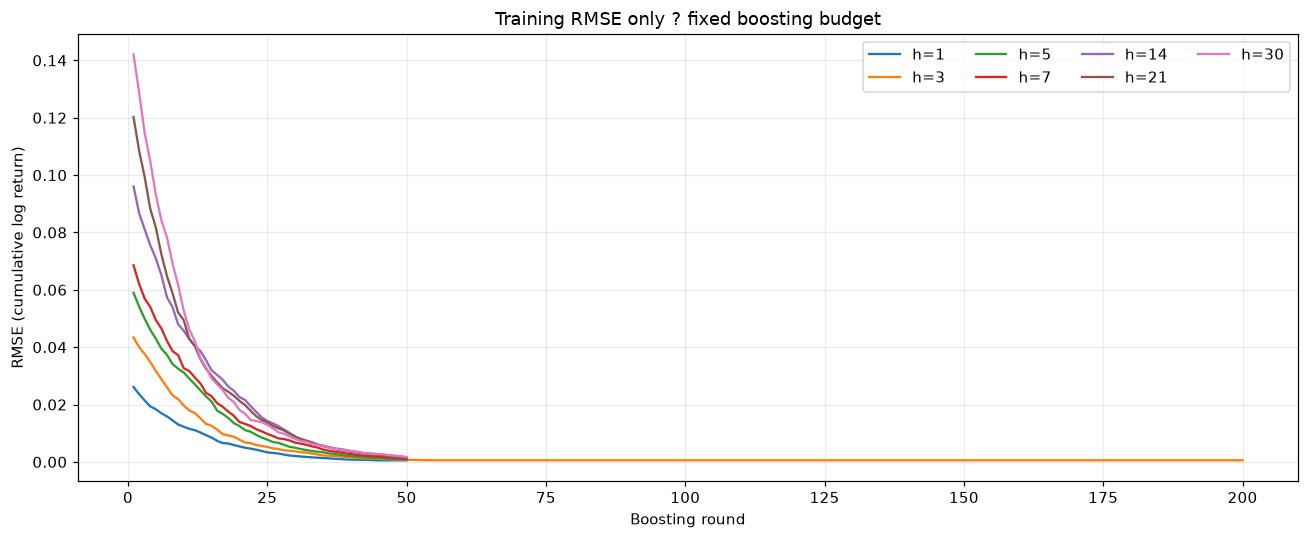

In [9]:
models, frozen_hashes, curve_rows, fit_rows = {}, {}, [], []
for h in HORIZONS:
    batch = training[h]
    assert batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    model = XGBRegressor(**xgb_parameters_for_horizon(h))
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        model.fit(batch['X'],batch['y'],eval_set=[(batch['X'],batch['y'])],verbose=False)
        xgb_verify_selected_fit(model, h, batch['X'], batch['y'])
    curve = np.asarray(model.evals_result()['validation_0']['rmse'])
    assert len(curve)==int(xgb_selected_parameters.loc[h, 'n_estimators']) and np.isfinite(curve).all()
    models[h]=model
    model.save_model(MODEL_DIR/f'xgb_h{h}.json')
    frozen_hashes[h]=model_digest(model)
    curve_rows.extend(dict(h=h,round=j+1,train_rmse=float(value)) for j,value in enumerate(curve))
    fit_rows.append(dict(h=h,n_train=len(batch['y']),n_rounds=len(curve),
        initial_train_RMSE=float(curve[0]),final_train_RMSE=float(curve[-1]),
        decreases_every_round=bool((np.diff(curve)<=1e-10).all()),
        warnings=' | '.join(str(w.message) for w in captured)))
    print(f'Fitted h={h}: {len(batch["y"])} samples, {len(curve)} rounds')
training_curve = pd.DataFrame(curve_rows)
fit_summary = pd.DataFrame(fit_rows)
save_table(training_curve,'training_curve.csv')
save_table(fit_summary,'fit_summary.csv')
display(fit_summary)
fig,ax=plt.subplots()
for h in HORIZONS:
    group=training_curve.loc[training_curve.h.eq(h)]
    ax.plot(group['round'],group.train_rmse,label=f'h={h}')
ax.set(title='Training RMSE only ? fixed boosting budget',xlabel='Boosting round',ylabel='RMSE (cumulative log return)')
ax.legend(ncol=4)
save_figure(fig,'06_training_curve.png')

### 7.1 XGBoost PI 95% - Train-only quantile models

The existing squared-error point models and forecasts remain unchanged. Separate `reg:quantileerror` models estimate the 2.5% and 97.5% quantiles of cumulative log returns for horizons 1 through 30. They use the same Train windows, original fixed tree settings and budgets, with no validation, early stopping, Test tuning or all-data refit.

Columns `xgb_lo95` and `xgb_hi95` are the nominal central 95% prediction bounds in the original price units. Quantile crossings are disclosed and resolved by a fixed row-wise ordering before exponentiation. The original point forecast is not used to stretch bounds.

These are estimated quantile intervals, not conformally calibrated intervals or a guarantee of 95% coverage under time dependence or regime changes. Test coverage below is reporting only and never changes the bounds.

Method reference: [Official XGBoost quantile regression example](https://xgboost.readthedocs.io/en/release_2.0.0/python/examples/quantile_regression.html).


In [10]:
# Nominal central 95% prediction intervals from separate Train-only quantile models.
# Do not tune or calibrate these bounds using Test outcomes.
assert tuple(int(v) for v in version('xgboost').split('.')[:2]) >= (2, 0)
pi_params = dict(XGB_PARAMS)
pi_params.update(objective='reg:quantileerror', quantile_alpha=XGB_PI_QUANTILES)
assert XGB_PARAMS['objective'] == 'reg:squarederror'
xgb_pi_models, xgb_pi_hashes, xgb_pi_fit_rows = {}, {}, []
xgb_pi_crossing_rows = []
for h in range(1, max(DAILY_FORECAST_WINDOWS)+1):
    pi_origins = np.arange(LOOKBACK, TRAIN_END_IDX-h+1)
    pi_input_idx = pi_origins[:, None] - np.arange(LOOKBACK)[None, :]
    pi_target_idx = pi_origins+h
    assert pi_input_idx.min() >= 1 and pi_target_idx.max() == TRAIN_END_IDX
    assert (pi_input_idx <= pi_origins[:, None]).all()
    assert len(pi_origins) == n_train-LOOKBACK-h
    pi_X = log_ret.to_numpy()[pi_input_idx]
    pi_y = np.asarray(log_price)[pi_target_idx]-np.asarray(log_price)[pi_origins]
    assert np.isfinite(pi_X).all() and np.isfinite(pi_y).all()
    pi_X = pd.DataFrame(pi_X, columns=feature_names, index=df.index[pi_origins])
    pi_model = XGBRegressor(**pi_params)
    with warnings.catch_warnings(record=True) as pi_warnings:
        warnings.simplefilter('always')
        pi_model.fit(pi_X, pi_y, verbose=False)
    assert pi_model.get_booster().num_boosted_rounds() == XGB_PARAMS['n_estimators']
    xgb_pi_models[h] = pi_model
    xgb_pi_hashes[h] = model_digest(pi_model)
    xgb_pi_fit_rows.append(dict(h=h, n_train=len(pi_origins),
        input_max_index=int(pi_input_idx.max()), target_max_index=int(pi_target_idx.max()),
        target_max_date=df.index[pi_target_idx.max()], lower_quantile=XGB_PI_QUANTILES[0],
        upper_quantile=XGB_PI_QUANTILES[1], nominal_coverage=1-XGB_PI_ALPHA,
        warnings=' | '.join(str(w.message) for w in pi_warnings)))
    pi_model.save_model(MODEL_DIR/f'xgb_pi_h{h}.json')
xgb_pi_fit_audit = pd.DataFrame(xgb_pi_fit_rows)
save_table(xgb_pi_fit_audit, 'xgb_pi_training_audit.csv')
display(Markdown('**PI models: Train-only cumulative-return quantiles, fixed budgets**'))
show_scroll_table(xgb_pi_fit_audit)

def attach_xgb_pi(frame, label):
    result = frame.copy(deep=True)
    previous_columns = list(frame.columns)
    lower = np.empty(len(frame), dtype=float)
    upper = np.empty(len(frame), dtype=float)
    for h in sorted(frame['h'].unique()):
        positions = np.flatnonzero(frame['h'].to_numpy() == h)
        origins = df.index.get_indexer(pd.to_datetime(frame['origin_date'].iloc[positions]))
        assert (origins >= LOOKBACK).all()
        idx = origins[:, None] - np.arange(LOOKBACK)[None, :]
        assert idx.min() >= 1 and (idx <= origins[:, None]).all()
        X = log_ret.to_numpy()[idx]
        X = pd.DataFrame(X, columns=feature_names)
        pi_model = xgb_pi_models[int(h)]
        assert model_digest(pi_model) == xgb_pi_hashes[int(h)]
        quantiles = pi_model.predict(X).astype(np.float64)
        assert quantiles.shape == (len(positions), 2) and np.isfinite(quantiles).all()
        crossed = quantiles[:, 0] > quantiles[:, 1]
        # Fixed monotone rearrangement; log ordering is preserved by exponentiation.
        ordered = np.sort(quantiles, axis=1)
        anchors = frame['price_origin'].iloc[positions].to_numpy(dtype=float)
        lower[positions] = anchors*np.exp(ordered[:, 0])
        upper[positions] = anchors*np.exp(ordered[:, 1])
        assert model_digest(pi_model) == xgb_pi_hashes[int(h)]
        xgb_pi_crossing_rows.append(dict(table=label, h=int(h), n=len(positions),
            raw_quantile_crossings=int(crossed.sum()), action='Fixed row-wise quantile ordering'))
    result['xgb_lo95'] = lower
    result['xgb_hi95'] = upper
    assert np.isfinite(result[['xgb_lo95','xgb_hi95']]).all().all()
    assert (result.xgb_lo95 > 0).all() and (result.xgb_lo95 <= result.xgb_hi95).all()
    # Preserve every existing point forecast, actual, date and row exactly.
    pd.testing.assert_frame_equal(result[previous_columns], frame)
    save_table(pd.DataFrame(xgb_pi_crossing_rows), 'xgb_pi_crossing_audit.csv')
    return result


**PI models: Train-only cumulative-return quantiles, fixed budgets**

h,n_train,input_max_index,target_max_index,target_max_date,lower_quantile,upper_quantile,nominal_coverage,warnings
1,1476,1515,1516,2025-08-25,0.03,0.97,0.95,
2,1475,1514,1516,2025-08-25,0.03,0.97,0.95,
3,1474,1513,1516,2025-08-25,0.03,0.97,0.95,
4,1473,1512,1516,2025-08-25,0.03,0.97,0.95,
5,1472,1511,1516,2025-08-25,0.03,0.97,0.95,
6,1471,1510,1516,2025-08-25,0.03,0.97,0.95,
7,1470,1509,1516,2025-08-25,0.03,0.97,0.95,
8,1469,1508,1516,2025-08-25,0.03,0.97,0.95,
9,1468,1507,1516,2025-08-25,0.03,0.97,0.95,
10,1467,1506,1516,2025-08-25,0.03,0.97,0.95,


## Step 8 Rolling-origin Test forecasting with fixed trees

In [11]:
test_origins = np.arange(TRAIN_END_IDX,n-1)
forecast_rows,predicted_returns = [],{}
for h in HORIZONS:
    origins = test_origins[test_origins+h<n]
    input_idx = origins[:,None]-np.arange(LOOKBACK)[None,:]
    assert (input_idx<=origins[:,None]).all() and input_idx.min()>=1
    X_test = pd.DataFrame(log_ret.to_numpy()[input_idx],columns=feature_names)
    assert model_digest(models[h])==frozen_hashes[h]
    r_hat = models[h].predict(X_test).astype(float)
    predicted_returns[h]=r_hat
    prices_origin = df['Price'].iloc[origins].to_numpy()
    prices_hat = prices_origin*np.exp(r_hat)
    for pos,origin in enumerate(origins):
        forecast_rows.append(dict(origin_date=df.index[origin],h=h,target_date=df.index[origin+h],
            price_origin=prices_origin[pos],actual=df['Price'].iloc[origin+h],xgb_fc=prices_hat[pos]))
    assert model_digest(models[h])==frozen_hashes[h]
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert ((forecasts['target_date']-forecasts['origin_date']).dt.days==forecasts['h']).all()
assert forecasts['target_date'].between(df.index[n_train],df.index[-1]).all()
forecasts = attach_xgb_pi(forecasts, 'test')
save_table(forecasts,'forecasts_long.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())

,n_points
h,
1,380
3,378
5,376
7,374
14,367
21,360
30,351


### Step 8.1 Test forecast tables by horizon
`origin_date` is the last observed day available to the model; `target_date = origin_date + h`. `actual` is the observed price used solely to score forecasts. These tables end within the observed dataset, so they do not describe unseen future dates.

In [12]:
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'#### h={h} calendar days ? {len(group)} Test forecasts'))
    show_scroll_table(group)

#### h=1 calendar days ? 380 Test forecasts

origin_date,h,target_date,price_origin,actual,xgb_fc,xgb_lo95,xgb_hi95
2025-08-25,1,2025-08-26,"110,118.40","111,768.60","108,775.78","105,046.70","113,456.57"
2025-08-26,1,2025-08-27,"111,768.60","111,255.60","114,100.98","107,256.33","116,559.25"
2025-08-27,1,2025-08-28,"111,255.60","112,568.90","111,694.53","106,824.10","115,690.89"
2025-08-28,1,2025-08-29,"112,568.90","108,355.60","112,904.24","108,299.62","116,997.01"
2025-08-29,1,2025-08-30,"108,355.60","108,818.10","107,633.37","103,714.28","113,296.73"
2025-08-30,1,2025-08-31,"108,818.10","108,226.80","109,158.20","107,159.78","111,952.38"
2025-08-31,1,2025-09-01,"108,226.80","109,243.30","107,820.74","104,545.03","110,797.77"
2025-09-01,1,2025-09-02,"109,243.30","111,218.30","109,818.34","107,567.12","113,747.28"
2025-09-02,1,2025-09-03,"111,218.30","111,716.50","110,534.70","107,298.66","115,167.12"
2025-09-03,1,2025-09-04,"111,716.50","110,712.70","112,004.59","108,146.39","114,912.31"


#### h=3 calendar days ? 378 Test forecasts

origin_date,h,target_date,price_origin,actual,xgb_fc,xgb_lo95,xgb_hi95
2025-08-25,3,2025-08-28,"110,118.40","112,568.90","111,563.53","103,100.10","117,740.41"
2025-08-26,3,2025-08-29,"111,768.60","108,355.60","111,334.07","109,727.96","121,255.72"
2025-08-27,3,2025-08-30,"111,255.60","108,818.10","110,757.34","104,105.29","119,735.61"
2025-08-28,3,2025-08-31,"112,568.90","108,226.80","113,842.82","105,869.84","122,142.01"
2025-08-29,3,2025-09-01,"108,355.60","109,243.30","107,325.61","103,831.35","116,149.14"
2025-08-30,3,2025-09-02,"108,818.10","111,218.30","108,095.18","104,506.63","119,917.72"
2025-08-31,3,2025-09-03,"108,226.80","111,716.50","109,495.17","102,312.73","115,858.45"
2025-09-01,3,2025-09-04,"109,243.30","110,712.70","112,068.83","102,512.37","118,164.16"
2025-09-02,3,2025-09-05,"111,218.30","110,652.20","115,738.05","104,950.98","118,995.40"
2025-09-03,3,2025-09-06,"111,716.50","110,194.40","114,190.39","107,763.86","124,874.84"


#### h=5 calendar days ? 376 Test forecasts

origin_date,h,target_date,price_origin,actual,xgb_fc,xgb_lo95,xgb_hi95
2025-08-25,5,2025-08-30,"110,118.40","108,818.10","111,685.18","101,418.92","115,578.93"
2025-08-26,5,2025-08-31,"111,768.60","108,226.80","116,009.93","105,062.34","123,398.90"
2025-08-27,5,2025-09-01,"111,255.60","109,243.30","112,425.23","107,924.77","119,612.95"
2025-08-28,5,2025-09-02,"112,568.90","111,218.30","116,122.04","105,218.75","126,237.59"
2025-08-29,5,2025-09-03,"108,355.60","111,716.50","110,254.99","100,921.12","120,313.56"
2025-08-30,5,2025-09-04,"108,818.10","110,712.70","110,821.44","105,191.32","117,619.60"
2025-08-31,5,2025-09-05,"108,226.80","110,652.20","107,504.26","102,830.31","117,362.95"
2025-09-01,5,2025-09-06,"109,243.30","110,194.40","112,794.84","105,905.21","123,450.18"
2025-09-02,5,2025-09-07,"111,218.30","111,150.10","110,403.59","103,401.56","122,018.97"
2025-09-03,5,2025-09-08,"111,716.50","112,068.40","116,357.04","105,238.26","123,849.36"


... (4 outputs left out)

#### h=21 calendar days ? 360 Test forecasts

origin_date,h,target_date,price_origin,actual,xgb_fc,xgb_lo95,xgb_hi95
2025-08-25,21,2025-09-15,"110,118.40","115,362.10","117,332.63","98,147.03","131,065.60"
2025-08-26,21,2025-09-16,"111,768.60","116,795.90","129,985.39","97,223.47","137,101.43"
2025-08-27,21,2025-09-17,"111,255.60","116,425.90","112,256.23","103,354.51","126,758.25"
2025-08-28,21,2025-09-18,"112,568.90","117,086.00","116,426.00","101,482.55","133,015.68"
2025-08-29,21,2025-09-19,"108,355.60","115,649.00","113,710.49","93,977.95","120,847.78"
2025-08-30,21,2025-09-20,"108,818.10","115,699.20","108,220.13","100,914.32","127,303.77"
2025-08-31,21,2025-09-21,"108,226.80","115,243.00","106,512.96","95,539.59","130,775.25"
2025-09-01,21,2025-09-22,"109,243.30","112,673.00","115,027.66","95,602.86","139,371.01"
2025-09-02,21,2025-09-23,"111,218.30","112,002.60","108,864.93","100,010.98","132,853.63"
2025-09-03,21,2025-09-24,"111,716.50","113,307.10","111,747.77","102,458.17","119,891.57"


#### h=30 calendar days ? 351 Test forecasts

origin_date,h,target_date,price_origin,actual,xgb_fc,xgb_lo95,xgb_hi95
2025-08-25,30,2025-09-24,"110,118.40","113,307.10","123,418.09","96,188.12","128,223.78"
2025-08-26,30,2025-09-25,"111,768.60","109,016.30","117,571.00","96,072.45","136,414.15"
2025-08-27,30,2025-09-26,"111,255.60","109,662.20","108,196.92","96,037.68","129,982.56"
2025-08-28,30,2025-09-27,"112,568.90","109,652.80","108,847.57","98,135.69","130,706.17"
2025-08-29,30,2025-09-28,"108,355.60","112,174.60","110,780.77","92,865.82","126,415.02"
2025-08-30,30,2025-09-29,"108,818.10","114,357.50","104,512.75","95,453.43","131,553.24"
2025-08-31,30,2025-09-30,"108,226.80","114,048.50","106,453.59","93,956.90","133,082.16"
2025-09-01,30,2025-10-01,"109,243.30","118,576.20","111,251.50","92,726.82","127,781.01"
2025-09-02,30,2025-10-02,"111,218.30","120,566.10","109,896.27","93,934.88","129,722.01"
2025-09-03,30,2025-10-03,"111,716.50","122,224.20","105,911.60","94,450.99","134,912.34"


### Step 8.2 Future forecasts from the latest observed date
All horizons share the same latest origin. Models remain fitted on the original Train. No actual values or metrics exist yet for these future target dates.

In [13]:
latest_idx = n-1-np.arange(LOOKBACK)
latest_input = pd.DataFrame(log_ret.to_numpy()[latest_idx].reshape(1,LOOKBACK),columns=feature_names)
future_rows=[]
for h in HORIZONS:
    r_hat=float(models[h].predict(latest_input)[0])
    future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
        price_origin=float(df['Price'].iloc[-1]),xgb_fc=float(df['Price'].iloc[-1])*np.exp(r_hat)))
    assert model_digest(models[h])==frozen_hashes[h]
future_forecasts=pd.DataFrame(future_rows)
future_forecasts = attach_xgb_pi(future_forecasts, 'future_by_horizon')
save_table(future_forecasts,'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)

C:\Users\User\AppData\Local\Temp\ipykernel_13568\2926481797.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
C:\Users\User\AppData\Local\Temp\ipykernel_13568\2926481797.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
C:\Users\User\AppData\Local\Temp\ipykernel_13568\2926481797.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. 

origin_date,h,target_date,price_origin,xgb_fc,xgb_lo95,xgb_hi95
2026-09-09,1,2026-09-10,"78,297.00","78,676.42","75,280.59","81,594.32"
2026-09-09,3,2026-09-12,"78,297.00","78,888.22","74,148.61","81,353.93"
2026-09-09,5,2026-09-14,"78,297.00","78,577.47","72,360.46","87,035.10"
2026-09-09,7,2026-09-16,"78,297.00","81,319.36","75,204.10","92,242.75"
2026-09-09,14,2026-09-23,"78,297.00","84,126.54","75,122.02","96,858.34"
2026-09-09,21,2026-09-30,"78,297.00","86,290.35","70,829.60","97,081.66"
2026-09-09,30,2026-10-09,"78,297.00","81,558.33","69,348.57","89,382.88"


### 8.3 Daily future forecast tables - next 7 and 30 calendar days
Direct cumulative-return forecasts for every day. Reuses existing horizon models; fits only missing horizons using the original Train-only prescription and fixed settings. No interpolation, validation, Test tuning or refitting of existing models.

All rows share the last observed origin. Prices are in USD. These models do not supply calibrated 95% prediction intervals.
Exports: `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under this notebook's output directory.


In [14]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
latest_origin = pd.Timestamp(df.index[-1])
latest_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex([
    pd.Timestamp(latest_origin.to_datetime64() + np.timedelta64(h, 'D'))
    for h in range(1, daily_steps + 1)
])
# Fit only missing direct horizons on Train with the original fixed parameters.
daily_models = {h: models[h] for h in HORIZONS}
daily_hashes = {h: frozen_hashes[h] for h in HORIZONS}
daily_fit_rows = []
for h in range(1, daily_steps + 1):
    if h in models:
        continue
    origins = np.arange(LOOKBACK, TRAIN_END_IDX - h + 1)
    input_idx = origins[:, None] - np.arange(LOOKBACK)[None, :]
    target_idx = origins + h
    assert input_idx.min() >= 1 and target_idx.max() <= TRAIN_END_IDX
    assert (input_idx <= origins[:, None]).all()
    X = pd.DataFrame(train_returns.to_numpy()[input_idx], columns=feature_names,
                     index=df.index[origins])
    y = train_log.iloc[target_idx].to_numpy() - train_log.iloc[origins].to_numpy()
    assert np.isfinite(X.to_numpy()).all() and np.isfinite(y).all()
    model = XGBRegressor(**xgb_parameters_for_horizon(h))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, y, eval_set=[(X, y)], verbose=False)
        xgb_verify_selected_fit(model, h, X, y)
    assert model.get_booster().num_boosted_rounds() == int(xgb_selected_parameters.loc[h, 'n_estimators'])
    daily_models[h] = model
    daily_hashes[h] = model_digest(model)
    model.save_model(MODEL_DIR/f'xgb_h{h}.json')
    daily_fit_rows.append(dict(h=h, n_train=len(origins),
        target_max_idx=int(target_idx.max()), target_max_date=df.index[target_idx.max()],
        n_estimators=model.get_booster().num_boosted_rounds(),
        warnings=' | '.join(str(w.message) for w in caught)))
save_table(pd.DataFrame(daily_fit_rows), 'daily_additional_fit_audit.csv')
latest_idx = n - 1 - np.arange(LOOKBACK)
latest_input = pd.DataFrame(log_ret.to_numpy()[latest_idx].reshape(1, LOOKBACK), columns=feature_names)
daily_values = []
for h in range(1, daily_steps + 1):
    assert model_digest(daily_models[h]) == daily_hashes[h]
    r_hat = float(daily_models[h].predict(latest_input)[0])
    daily_values.append(latest_price*np.exp(r_hat))
    assert model_digest(daily_models[h]) == daily_hashes[h]
future_forecast_daily = pd.DataFrame(dict(origin_date=latest_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=latest_price, xgb_fc=daily_values))
future_forecast_daily = attach_xgb_pi(future_forecast_daily, 'future_daily')
daily_forecast_columns = ['xgb_fc']
assert len(future_forecast_daily) == daily_steps
assert ((future_forecast_daily['target_date'] - latest_origin).dt.days == future_forecast_daily['h']).all()
assert not future_forecast_daily['target_date'].duplicated().any()
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(
    future_forecast_daily.set_index('h').loc[HORIZONS, daily_forecast_columns],
    future_forecasts.set_index('h').loc[HORIZONS, daily_forecast_columns], rtol=1e-12)
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} calendar days - origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))

**Next 7 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,xgb_fc,xgb_lo95,xgb_hi95
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,676.42","75,280.59","81,594.32"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,443.07","74,097.44","80,713.04"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,888.22","74,148.61","81,353.93"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","77,801.78","74,877.10","83,304.04"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,577.47","72,360.46","87,035.10"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","78,149.91","74,715.90","87,823.32"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","81,319.36","75,204.10","92,242.75"


**Next 30 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,xgb_fc,xgb_lo95,xgb_hi95
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,676.42","75,280.59","81,594.32"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,443.07","74,097.44","80,713.04"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,888.22","74,148.61","81,353.93"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","77,801.78","74,877.10","83,304.04"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,577.47","72,360.46","87,035.10"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","78,149.91","74,715.90","87,823.32"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","81,319.36","75,204.10","92,242.75"
2026-09-09,8,2026-09-17,Thursday,"78,297.00","82,069.13","72,329.91","89,765.66"
2026-09-09,9,2026-09-18,Friday,"78,297.00","79,768.13","73,811.73","94,390.44"
2026-09-09,10,2026-09-19,Saturday,"78,297.00","81,345.00","70,336.26","97,860.27"


### 8.4 Future forecast plots from the latest observed date

These 7- and 30-step plots reuse the future forecast tables above and the original Train-fitted model. The dashed line marks the last observed date; every forecast target lies after it. The left panel provides recent price history and the right panel enlarges the future path.

**Step unit:** calendar days. Daily calendar dates.

**Uncertainty:** Nominal quantile interval; coverage is not guaranteed.

**Rendering note:** Added outputs were rendered from saved forecasts without retraining. On Run All, this cell uses the freshly computed in-memory forecast table. The forecast origin is the dataset end date, not the current wall-clock date.

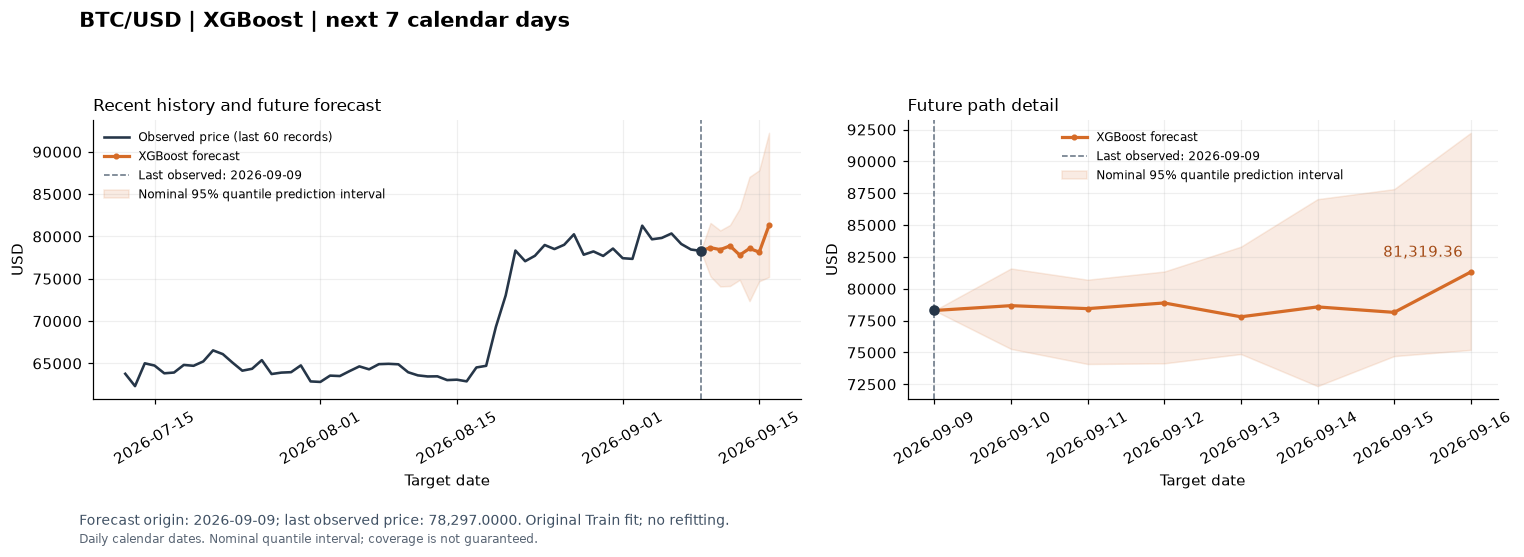

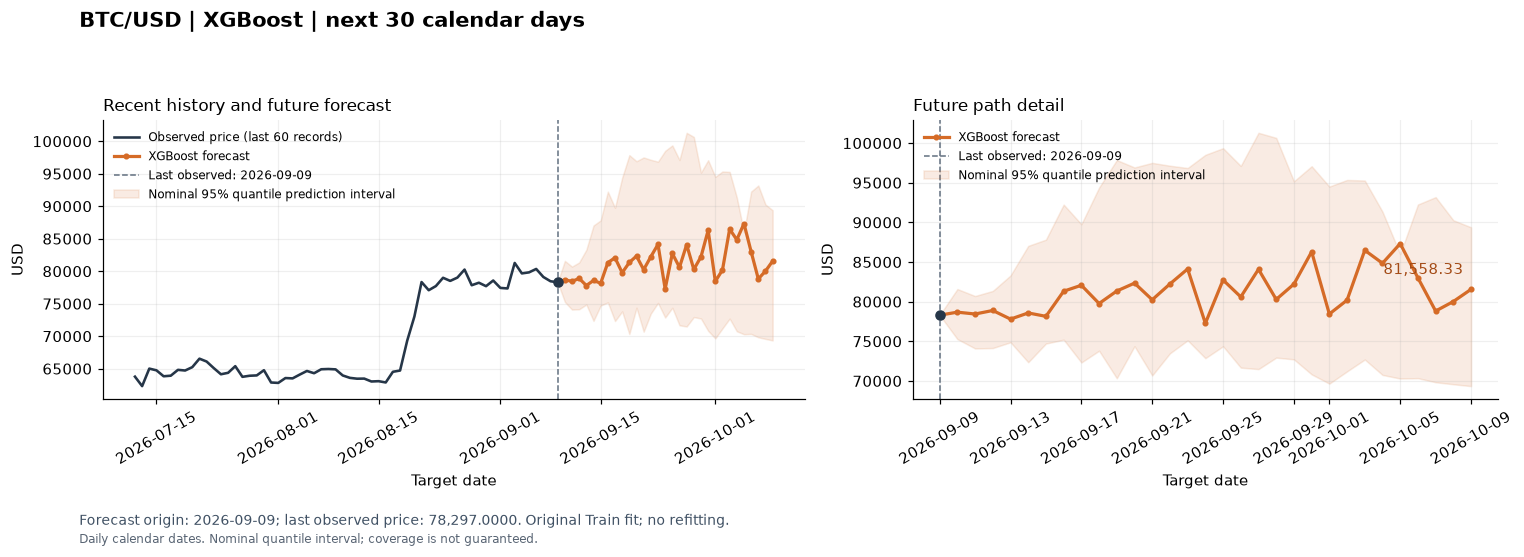

In [15]:
# Plot the already computed future path; no fitting or new inference.
FUTURE_MODEL_LABEL = 'XGBoost'
FUTURE_UNCERTAINTY_NOTE = 'Nominal quantile interval; coverage is not guaranteed.'
FUTURE_PLOT_LABEL = 'BTC/USD'
FUTURE_PLOT_UNIT = 'USD'
FUTURE_STEP_LABEL = 'calendar days'
FUTURE_DATE_NOTE = 'Daily calendar dates.'

def plot_model_future_path(history, future_path, steps):
    path = future_path.sort_values('h').iloc[:steps].copy()
    origin = pd.Timestamp(history.index[-1])
    last_actual = float(history.iloc[-1])
    forecast_column = next(c for c in ['svr_fc', 'xgb_fc', 'patchtst_fc_ens', 'forecast'] if c in path)
    seed_columns = [column for column in path if column.startswith(('patchtst_fc_seed', 'forecast_seed'))]
    dates = pd.DatetimeIndex(pd.to_datetime(path['target_date']))
    values = path[forecast_column].to_numpy(dtype=float)
    assert len(path) == steps and path['h'].tolist() == list(range(1, steps + 1))
    assert dates.is_unique and dates.is_monotonic_increasing and (dates > origin).all()
    assert (pd.to_datetime(path['origin_date']) == origin).all()
    assert np.isfinite(values).all() and (values > 0).all()
    np.testing.assert_allclose(path['price_origin'], last_actual, rtol=1e-12)

    joined_dates = pd.DatetimeIndex([origin, *dates])
    joined_forecast = np.r_[last_actual, values]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
    recent = history.iloc[-60:]
    axes[0].plot(recent.index, recent, color='#263648', linewidth=1.7, label='Observed price (last 60 records)')
    for ax in axes:
        ax.plot(joined_dates, joined_forecast, color='#d56b27', linewidth=2.1,
                marker='o', markersize=3, label=f'{FUTURE_MODEL_LABEL} forecast')
        ax.axvline(origin, color='#627080', linestyle='--', linewidth=1,
                   label=f'Last observed: {origin:%Y-%m-%d}')
        ax.scatter([origin], [last_actual], color='#263648', s=35, zorder=4)
        if seed_columns:
            seed_values = path[seed_columns].to_numpy(dtype=float)
            assert np.isfinite(seed_values).all() and (seed_values > 0).all()
            low = np.r_[last_actual, seed_values.min(axis=1)]
            high = np.r_[last_actual, seed_values.max(axis=1)]
            ax.fill_between(joined_dates, low, high, color='#d56b27', alpha=.13,
                            label=f'Range across {len(seed_columns)} seeds')
        if {'xgb_lo95', 'xgb_hi95'}.issubset(path.columns):
            interval = path[['xgb_lo95', 'xgb_hi95']].to_numpy(dtype=float)
            assert np.isfinite(interval).all() and (interval > 0).all()
            assert (interval[:, 0] <= interval[:, 1]).all()
            ax.fill_between(joined_dates, np.r_[last_actual, interval[:, 0]],
                            np.r_[last_actual, interval[:, 1]], color='#d56b27', alpha=.13,
                            label='Nominal 95% quantile prediction interval')
        ax.set(ylabel=FUTURE_PLOT_UNIT, xlabel='Target date')
        ax.grid(alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='x', labelrotation=30)
    axes[0].set_title('Recent history and future forecast', loc='left', fontsize=11)
    axes[1].set_title('Future path detail', loc='left', fontsize=11)
    endpoint_label = f'{values[-1]:,.6f}' if FUTURE_PLOT_LABEL == 'USD/EUR' else f'{values[-1]:,.2f}'
    axes[1].annotate(endpoint_label, xy=(dates[-1], values[-1]),
                     xytext=(-5, 10), textcoords='offset points', ha='right', color='#a34a15')
    axes[0].legend(loc='best', fontsize=8, frameon=False)
    axes[1].legend(loc='best', fontsize=8, frameon=False)
    fig.suptitle(f'{FUTURE_PLOT_LABEL} | {FUTURE_MODEL_LABEL} | next {steps} {FUTURE_STEP_LABEL}',
                 fontsize=14, fontweight='bold', x=.055, ha='left')
    fig.text(.055, .045, f'Forecast origin: {origin:%Y-%m-%d}; last observed price: {last_actual:,.4f}. '
             'Original Train fit; no refitting.', fontsize=9, color='#405164')
    fig.text(.055, .012, FUTURE_DATE_NOTE + ' ' + FUTURE_UNCERTAINTY_NOTE,
             fontsize=8, color='#596574')
    fig.tight_layout(rect=(0, .08, 1, .92))
    return fig

for future_steps in [7, 30]:
    future_fig = plot_model_future_path(df['Price'], future_forecast_daily, future_steps)
    plt.show()
    plt.close(future_fig)


<a id="task1-future-metrics"></a>

### 8.4.1 — Task 1: Original archived future forecast RMSE/MAPE

**Source:** original saved forecasts from **9 September 2026**, evaluated against `Bitcoin Historical Data (2).csv` in `ACTUAL_FOR_PREDICT`. Match by the original target dates; no retraining, calendar changes, date shifting or price imputation. These future forecasts have now been observed; this evaluation is separate from the historical Test set.

The tables show (A) actual/forecast pairs, (B) requested horizons, and (C) whole 7/30-step paths. **One origin gives n=1 per horizon**, so per-horizon RMSE is absolute error and MAPE is the single percentage error. Path metrics combine different horizons from that origin; they are not rolling-origin Test scores. Missing dates stay N/A and partial-window counts are explicit.

**Units:** RMSE in USD; MAPE in percent. **Forecast precision:** full precision saved forecast CSV; checked against saved notebook output. LSTM/Transformer use the original predefined-seed ensemble forecast, not an average of seed metrics. Archive values are embedded in the next cell and cannot be overwritten by later inference.

[Go to Task 2 — Test set](#task2-test-metrics)


In [16]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

task1_model = 'XGBOOST'
task1_asset = 'BTC'
task1_unit = 'USD'
task1_horizons = [1, 3, 5, 7, 14, 21, 30]
task1_archive_provenance = {'source': 'OUTPUT\\outputs_xgb\\tables\\future_forecast_daily_30d.csv', 'precision': 'full precision saved forecast CSV; checked against saved notebook output', 'original_notebook_sha256': 'a31b36859e111bbd0e6b1195814bbd1df3714d144ccd9e6c4cf69030154b1d0c', 'original_data_source': 'CSV/Bitcoin Historical Data.csv', 'original_data_sha256': '26ac572d5c806c7d2be814fa93c3b0de970786a01e8d813998292f104d9fcc15'}
task1_archive = pd.DataFrame(json.loads('[{"origin_date": "2026-09-09", "h": 1, "target_date": "2026-09-10", "Forecast": 77899.46288643408}, {"origin_date": "2026-09-09", "h": 2, "target_date": "2026-09-11", "Forecast": 77903.16931236055}, {"origin_date": "2026-09-09", "h": 3, "target_date": "2026-09-12", "Forecast": 79282.26940926666}, {"origin_date": "2026-09-09", "h": 4, "target_date": "2026-09-13", "Forecast": 77801.77925631951}, {"origin_date": "2026-09-09", "h": 5, "target_date": "2026-09-14", "Forecast": 80534.99537682715}, {"origin_date": "2026-09-09", "h": 6, "target_date": "2026-09-15", "Forecast": 82583.34070341875}, {"origin_date": "2026-09-09", "h": 7, "target_date": "2026-09-16", "Forecast": 82800.61462439861}, {"origin_date": "2026-09-09", "h": 8, "target_date": "2026-09-17", "Forecast": 78735.01663046927}, {"origin_date": "2026-09-09", "h": 9, "target_date": "2026-09-18", "Forecast": 79194.32409099424}, {"origin_date": "2026-09-09", "h": 10, "target_date": "2026-09-19", "Forecast": 81477.22102980071}, {"origin_date": "2026-09-09", "h": 11, "target_date": "2026-09-20", "Forecast": 81879.5990829685}, {"origin_date": "2026-09-09", "h": 12, "target_date": "2026-09-21", "Forecast": 83657.66092406499}, {"origin_date": "2026-09-09", "h": 13, "target_date": "2026-09-22", "Forecast": 80774.02702235612}, {"origin_date": "2026-09-09", "h": 14, "target_date": "2026-09-23", "Forecast": 82576.36818038582}, {"origin_date": "2026-09-09", "h": 15, "target_date": "2026-09-24", "Forecast": 80948.33735315906}, {"origin_date": "2026-09-09", "h": 16, "target_date": "2026-09-25", "Forecast": 83481.08019195512}, {"origin_date": "2026-09-09", "h": 17, "target_date": "2026-09-26", "Forecast": 81409.42387226979}, {"origin_date": "2026-09-09", "h": 18, "target_date": "2026-09-27", "Forecast": 84064.78319603254}, {"origin_date": "2026-09-09", "h": 19, "target_date": "2026-09-28", "Forecast": 82622.61686223322}, {"origin_date": "2026-09-09", "h": 20, "target_date": "2026-09-29", "Forecast": 88280.75666599366}, {"origin_date": "2026-09-09", "h": 21, "target_date": "2026-09-30", "Forecast": 79899.31718241141}, {"origin_date": "2026-09-09", "h": 22, "target_date": "2026-10-01", "Forecast": 84804.30030820437}, {"origin_date": "2026-09-09", "h": 23, "target_date": "2026-10-02", "Forecast": 87071.93358514366}, {"origin_date": "2026-09-09", "h": 24, "target_date": "2026-10-03", "Forecast": 82128.93959135063}, {"origin_date": "2026-09-09", "h": 25, "target_date": "2026-10-04", "Forecast": 85336.01952831713}, {"origin_date": "2026-09-09", "h": 26, "target_date": "2026-10-05", "Forecast": 79912.05009654048}, {"origin_date": "2026-09-09", "h": 27, "target_date": "2026-10-06", "Forecast": 82923.66714917333}, {"origin_date": "2026-09-09", "h": 28, "target_date": "2026-10-07", "Forecast": 76583.89354663933}, {"origin_date": "2026-09-09", "h": 29, "target_date": "2026-10-08", "Forecast": 80768.63089231838}, {"origin_date": "2026-09-09", "h": 30, "target_date": "2026-10-09", "Forecast": 79270.19142211344}]'))
task1_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task1_actual_path = task1_root / 'ACTUAL_FOR_PREDICT' / 'Bitcoin Historical Data (2).csv'
task1_actual = pd.read_csv(task1_actual_path, encoding='utf-8-sig')
task1_actual['target_date'] = pd.to_datetime(task1_actual['Date'], format='%m/%d/%Y', errors='raise')
task1_actual['Actual'] = pd.to_numeric(task1_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert task1_actual['target_date'].notna().all() and not task1_actual['target_date'].duplicated().any()
assert np.isfinite(task1_actual['Actual']).all() and task1_actual['Actual'].gt(0).all()
for task1_column in ['origin_date', 'target_date']:
    task1_archive[task1_column] = pd.to_datetime(task1_archive[task1_column], errors='raise')
assert task1_archive['h'].tolist() == list(range(1, 31))
assert task1_archive['origin_date'].nunique() == 1 and task1_archive['target_date'].is_unique
assert task1_archive['target_date'].is_monotonic_increasing
assert (task1_archive['target_date'] > task1_archive['origin_date']).all()
assert np.isfinite(task1_archive['Forecast']).all() and task1_archive['Forecast'].gt(0).all()

task1_comparison = task1_archive.merge(task1_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(task1_comparison['Forecast'], task1_archive['Forecast'])
assert len(task1_comparison) == 30
task1_comparison['Error'] = task1_comparison['Forecast'] - task1_comparison['Actual']
task1_comparison['APE (%)'] = 100 * task1_comparison['Error'].abs() / task1_comparison['Actual']
task1_comparison['Status'] = np.where(task1_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
task1_horizon_metrics = task1_comparison.loc[task1_comparison.h.isin(task1_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
task1_horizon_metrics['n_actuals'] = task1_horizon_metrics['Actual'].notna().astype(int)
task1_horizon_metrics['RMSE'] = (task1_horizon_metrics['Forecast'] - task1_horizon_metrics['Actual']).abs()
task1_horizon_metrics['RMSE_unit'] = task1_unit
task1_horizon_metrics['MAPE (%)'] = 100 * task1_horizon_metrics['RMSE'] / task1_horizon_metrics['Actual']
task1_window_rows = []
for task1_window in [7, 30]:
    task1_part = task1_comparison.loc[task1_comparison.h.le(task1_window)]
    task1_matched = task1_part.dropna(subset=['Actual'])
    task1_error = task1_matched['Forecast'].to_numpy() - task1_matched['Actual'].to_numpy()
    task1_window_rows.append(dict(window_steps=task1_window, n_expected=len(task1_part),
        n_actuals=len(task1_matched), n_missing=len(task1_part)-len(task1_matched),
        first_target_date=task1_part.target_date.min(), last_target_date=task1_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task1_error**2))) if len(task1_matched) else np.nan,
        RMSE_unit=task1_unit,
        MAPE_percent=float(100*np.mean(np.abs(task1_error/task1_matched['Actual'].to_numpy()))) if len(task1_matched) else np.nan,
        Status='Complete' if len(task1_part)==len(task1_matched) else 'Partial: matched dates only'))
task1_window_metrics = pd.DataFrame(task1_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
task1_missing = task1_comparison.loc[task1_comparison.Actual.isna(), ['h', 'target_date']].copy()

def task1_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Original future forecast / actual pairs (prices in ' + task1_unit + ')**'))
task1_show_table(task1_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
task1_show_table(task1_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
task1_show_table(task1_window_metrics)
if not task1_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    task1_show_table(task1_missing)
task1_output = task1_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future' / 'XGBOOST_BTC'
task1_output.mkdir(parents=True, exist_ok=True)
for task1_name, task1_frame in [('original_forecast_archive.csv', task1_archive),
        ('forecast_actual_pairs.csv', task1_comparison), ('metrics_by_horizon.csv', task1_horizon_metrics),
        ('metrics_7_30_steps.csv', task1_window_metrics), ('missing_actual_dates.csv', task1_missing)]:
    task1_frame.to_csv(task1_output / task1_name, index=False, encoding='utf-8-sig')
task1_provenance = dict(task1_archive_provenance, actual_source=str(task1_actual_path.relative_to(task1_root)),
    actual_sha256=hashlib.sha256(task1_actual_path.read_bytes()).hexdigest(),
    model=task1_model, asset=task1_asset, origin=str(task1_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(task1_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(task1_output / 'provenance.json').write_text(json.dumps(task1_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', task1_archive_provenance['source'])
print('Actual prices:', task1_actual_path.name, '| forecast origin:', task1_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', task1_output)


**Task 1A — Original future forecast / actual pairs (prices in USD)**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,"77,899.462886","76,565.100000","1,334.362886",1.742782,Matched original target date
2026-09-09,2,2026-09-11,"77,903.169312","77,220.500000",682.669312,0.884052,Matched original target date
2026-09-09,3,2026-09-12,"79,282.269409","77,282.400000","1,999.869409",2.587742,Matched original target date
2026-09-09,4,2026-09-13,"77,801.779256","76,843.500000",958.279256,1.247053,Matched original target date
2026-09-09,5,2026-09-14,"80,534.995377","78,185.300000","2,349.695377",3.005290,Matched original target date
2026-09-09,6,2026-09-15,"82,583.340703","75,620.400000","6,962.940703",9.207754,Matched original target date
2026-09-09,7,2026-09-16,"82,800.614624","76,191.400000","6,609.214624",8.674489,Matched original target date
2026-09-09,8,2026-09-17,"78,735.016630","76,439.900000","2,295.116630",3.002511,Matched original target date
2026-09-09,9,2026-09-18,"79,194.324091","80,882.000000","-1,687.675909",2.086590,Matched original target date
2026-09-09,10,2026-09-19,"81,477.221030","81,253.100000",224.121030,0.275831,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,"77,899.462886","76,565.100000",1,"1,334.362886",USD,1.742782
2026-09-09,3,2026-09-12,"79,282.269409","77,282.400000",1,"1,999.869409",USD,2.587742
2026-09-09,5,2026-09-14,"80,534.995377","78,185.300000",1,"2,349.695377",USD,3.005290
2026-09-09,7,2026-09-16,"82,800.614624","76,191.400000",1,"6,609.214624",USD,8.674489
2026-09-09,14,2026-09-23,"82,576.368180","84,394.400000",1,"1,818.031820",USD,2.154209
2026-09-09,21,2026-09-30,"79,899.317182","83,612.200000",1,"3,712.882818",USD,4.440599
2026-09-09,30,2026-10-09,"79,270.191422","82,623.600000",1,"3,353.408578",USD,4.058657


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-16,"3,870.209814",USD,3.907023,Complete
30,30,30,0,2026-09-10,2026-10-09,"3,298.698321",USD,3.206603,Complete


Forecast source: OUTPUT\outputs_xgb\tables\future_forecast_daily_30d.csv
Actual prices: Bitcoin Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future\XGBOOST_BTC


<a id="xgb-revised-future"></a>

### 8.4.2 — Revised Future RMSE/MAPE after Train-only XGBoost selection

Current rank-1 Train-selected point forecasts are evaluated against supplied actual prices here. Original archived-forecast results remain directly above. This is retrospective evaluation on already inspected dates, not a new unseen holdout. No actuals are used to tune the parameters, and missing target dates remain N/A.


In [17]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

xgb_revised_model = 'XGBOOST'
xgb_revised_asset = 'BTC'
xgb_revised_unit = 'USD'
xgb_revised_horizons = [1, 3, 5, 7, 14, 21, 30]
xgb_revised_archive_provenance = dict(source='Current Train-ranked XGBoost execution; full precision', precision='Retrospective rerun; parameters selected using Train only')
xgb_revised_archive = future_forecast_daily[['origin_date','h','target_date','xgb_fc']].copy().rename(columns={'xgb_fc':'Forecast'})
xgb_revised_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
xgb_revised_actual_path = xgb_revised_root / 'ACTUAL_FOR_PREDICT' / 'Bitcoin Historical Data (2).csv'
xgb_revised_actual = pd.read_csv(xgb_revised_actual_path, encoding='utf-8-sig')
xgb_revised_actual['target_date'] = pd.to_datetime(xgb_revised_actual['Date'], format='%m/%d/%Y', errors='raise')
xgb_revised_actual['Actual'] = pd.to_numeric(xgb_revised_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert xgb_revised_actual['target_date'].notna().all() and not xgb_revised_actual['target_date'].duplicated().any()
assert np.isfinite(xgb_revised_actual['Actual']).all() and xgb_revised_actual['Actual'].gt(0).all()
for xgb_revised_column in ['origin_date', 'target_date']:
    xgb_revised_archive[xgb_revised_column] = pd.to_datetime(xgb_revised_archive[xgb_revised_column], errors='raise')
assert xgb_revised_archive['h'].tolist() == list(range(1, 31))
assert xgb_revised_archive['origin_date'].nunique() == 1 and xgb_revised_archive['target_date'].is_unique
assert xgb_revised_archive['target_date'].is_monotonic_increasing
assert (xgb_revised_archive['target_date'] > xgb_revised_archive['origin_date']).all()
assert np.isfinite(xgb_revised_archive['Forecast']).all() and xgb_revised_archive['Forecast'].gt(0).all()

xgb_revised_comparison = xgb_revised_archive.merge(xgb_revised_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(xgb_revised_comparison['Forecast'], xgb_revised_archive['Forecast'])
assert len(xgb_revised_comparison) == 30
xgb_revised_comparison['Error'] = xgb_revised_comparison['Forecast'] - xgb_revised_comparison['Actual']
xgb_revised_comparison['APE (%)'] = 100 * xgb_revised_comparison['Error'].abs() / xgb_revised_comparison['Actual']
xgb_revised_comparison['Status'] = np.where(xgb_revised_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
xgb_revised_horizon_metrics = xgb_revised_comparison.loc[xgb_revised_comparison.h.isin(xgb_revised_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
xgb_revised_horizon_metrics['n_actuals'] = xgb_revised_horizon_metrics['Actual'].notna().astype(int)
xgb_revised_horizon_metrics['RMSE'] = (xgb_revised_horizon_metrics['Forecast'] - xgb_revised_horizon_metrics['Actual']).abs()
xgb_revised_horizon_metrics['RMSE_unit'] = xgb_revised_unit
xgb_revised_horizon_metrics['MAPE (%)'] = 100 * xgb_revised_horizon_metrics['RMSE'] / xgb_revised_horizon_metrics['Actual']
xgb_revised_window_rows = []
for xgb_revised_window in [7, 30]:
    xgb_revised_part = xgb_revised_comparison.loc[xgb_revised_comparison.h.le(xgb_revised_window)]
    xgb_revised_matched = xgb_revised_part.dropna(subset=['Actual'])
    xgb_revised_error = xgb_revised_matched['Forecast'].to_numpy() - xgb_revised_matched['Actual'].to_numpy()
    xgb_revised_window_rows.append(dict(window_steps=xgb_revised_window, n_expected=len(xgb_revised_part),
        n_actuals=len(xgb_revised_matched), n_missing=len(xgb_revised_part)-len(xgb_revised_matched),
        first_target_date=xgb_revised_part.target_date.min(), last_target_date=xgb_revised_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(xgb_revised_error**2))) if len(xgb_revised_matched) else np.nan,
        RMSE_unit=xgb_revised_unit,
        MAPE_percent=float(100*np.mean(np.abs(xgb_revised_error/xgb_revised_matched['Actual'].to_numpy()))) if len(xgb_revised_matched) else np.nan,
        Status='Complete' if len(xgb_revised_part)==len(xgb_revised_matched) else 'Partial: matched dates only'))
xgb_revised_window_metrics = pd.DataFrame(xgb_revised_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
xgb_revised_missing = xgb_revised_comparison.loc[xgb_revised_comparison.Actual.isna(), ['h', 'target_date']].copy()

def xgb_revised_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Revised Train-ranked XGBoost future forecast / actual pairs (prices in ' + xgb_revised_unit + ')**'))
xgb_revised_show_table(xgb_revised_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
xgb_revised_show_table(xgb_revised_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
xgb_revised_show_table(xgb_revised_window_metrics)
if not xgb_revised_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    xgb_revised_show_table(xgb_revised_missing)
xgb_revised_output = xgb_revised_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future_Revised_TrainSearch' / 'XGBOOST_BTC'
xgb_revised_output.mkdir(parents=True, exist_ok=True)
for xgb_revised_name, xgb_revised_frame in [('revised_forecast_snapshot.csv', xgb_revised_archive),
        ('forecast_actual_pairs.csv', xgb_revised_comparison), ('metrics_by_horizon.csv', xgb_revised_horizon_metrics),
        ('metrics_7_30_steps.csv', xgb_revised_window_metrics), ('missing_actual_dates.csv', xgb_revised_missing)]:
    xgb_revised_frame.to_csv(xgb_revised_output / xgb_revised_name, index=False, encoding='utf-8-sig')
xgb_revised_provenance = dict(xgb_revised_archive_provenance, actual_source=str(xgb_revised_actual_path.relative_to(xgb_revised_root)),
    actual_sha256=hashlib.sha256(xgb_revised_actual_path.read_bytes()).hexdigest(),
    model=xgb_revised_model, asset=xgb_revised_asset, origin=str(xgb_revised_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(xgb_revised_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(xgb_revised_output / 'provenance.json').write_text(json.dumps(xgb_revised_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', xgb_revised_archive_provenance['source'])
print('Actual prices:', xgb_revised_actual_path.name, '| forecast origin:', xgb_revised_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', xgb_revised_output)

print('RETROSPECTIVE XGBoost rerun: previously inspected Test/future periods; selection used Train only.')


**Task 1A — Revised Train-ranked XGBoost future forecast / actual pairs (prices in USD)**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,"78,676.424680","76,565.100000","2,111.324680",2.757555,Matched original target date
2026-09-09,2,2026-09-11,"78,443.066874","77,220.500000","1,222.566874",1.583215,Matched original target date
2026-09-09,3,2026-09-12,"78,888.216705","77,282.400000","1,605.816705",2.077856,Matched original target date
2026-09-09,4,2026-09-13,"77,801.779256","76,843.500000",958.279256,1.247053,Matched original target date
2026-09-09,5,2026-09-14,"78,577.469647","78,185.300000",392.169647,0.501590,Matched original target date
2026-09-09,6,2026-09-15,"78,149.907313","75,620.400000","2,529.507313",3.345007,Matched original target date
2026-09-09,7,2026-09-16,"81,319.355336","76,191.400000","5,127.955336",6.730360,Matched original target date
2026-09-09,8,2026-09-17,"82,069.133880","76,439.900000","5,629.233880",7.364261,Matched original target date
2026-09-09,9,2026-09-18,"79,768.130315","80,882.000000","-1,113.869685",1.377154,Matched original target date
2026-09-09,10,2026-09-19,"81,345.002190","81,253.100000",91.902190,0.113106,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,"78,676.424680","76,565.100000",1,"2,111.324680",USD,2.757555
2026-09-09,3,2026-09-12,"78,888.216705","77,282.400000",1,"1,605.816705",USD,2.077856
2026-09-09,5,2026-09-14,"78,577.469647","78,185.300000",1,392.169647,USD,0.501590
2026-09-09,7,2026-09-16,"81,319.355336","76,191.400000",1,"5,127.955336",USD,6.730360
2026-09-09,14,2026-09-23,"84,126.540855","84,394.400000",1,267.859145,USD,0.317390
2026-09-09,21,2026-09-30,"86,290.354543","83,612.200000",1,"2,678.154543",USD,3.203067
2026-09-09,30,2026-10-09,"81,558.333252","82,623.600000",1,"1,065.266748",USD,1.289301


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-16,"2,458.147918",USD,2.606091,Complete
30,30,30,0,2026-09-10,2026-10-09,"3,264.025782",USD,3.164426,Complete


Forecast source: Current Train-ranked XGBoost execution; full precision
Actual prices: Bitcoin Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future_Revised_TrainSearch\XGBOOST_BTC
RETROSPECTIVE XGBoost rerun: previously inspected Test/future periods; selection used Train only.


### 8.4 PI coverage on historical Test - reporting only

Nominal coverage is 95%; realized coverage and interval width are descriptive. Overlapping horizons, time dependence and regime changes limit interpretation. No settings are revised from this table.


In [18]:
xgb_pi_coverage_rows = []
for h, group in forecasts.groupby('h', sort=True):
    covered = group['actual'].between(group['xgb_lo95'], group['xgb_hi95'])
    xgb_pi_coverage_rows.append(dict(h=int(h), n=len(group), nominal_coverage_pct=95.,
        empirical_test_coverage_pct=float(100*covered.mean()),
        mean_interval_width=float((group['xgb_hi95']-group['xgb_lo95']).mean()),
        status='REPORTED', interpretation='Test reporting only; no recalibration or retuning'))
xgb_pi_test_coverage = pd.DataFrame(xgb_pi_coverage_rows)
save_table(xgb_pi_test_coverage, 'xgb_pi_test_coverage.csv')
display(xgb_pi_test_coverage)
display(Markdown('**Raw quantile crossing audit (ordering fixed before Test)**'))
display(pd.DataFrame(xgb_pi_crossing_rows))
assert all(model_digest(model) == xgb_pi_hashes[h]
           for h, model in xgb_pi_models.items())


,h,n,nominal_coverage_pct,empirical_test_coverage_pct,mean_interval_width,status,interpretation
0,1,380,95.0,88.947368,5774.071637,REPORTED,Test reporting only; no recalibration or retuning
1,3,378,95.0,85.449735,10140.641587,REPORTED,Test reporting only; no recalibration or retuning
2,5,376,95.0,84.308511,13134.335805,REPORTED,Test reporting only; no recalibration or retuning
3,7,374,95.0,87.433155,16220.142622,REPORTED,Test reporting only; no recalibration or retuning
4,14,367,95.0,77.929155,21081.259197,REPORTED,Test reporting only; no recalibration or retuning
5,21,360,95.0,78.333333,25969.705056,REPORTED,Test reporting only; no recalibration or retuning
6,30,351,95.0,74.358974,33344.273427,REPORTED,Test reporting only; no recalibration or retuning


**Raw quantile crossing audit (ordering fixed before Test)**

,table,h,n,raw_quantile_crossings,action
0,test,1,380,0,Fixed row-wise quantile ordering
1,test,3,378,0,Fixed row-wise quantile ordering
2,test,5,376,0,Fixed row-wise quantile ordering
3,test,7,374,0,Fixed row-wise quantile ordering
4,test,14,367,0,Fixed row-wise quantile ordering
5,test,21,360,0,Fixed row-wise quantile ordering
6,test,30,351,0,Fixed row-wise quantile ordering
7,future_by_horizon,1,1,0,Fixed row-wise quantile ordering
8,future_by_horizon,3,1,0,Fixed row-wise quantile ordering
9,future_by_horizon,5,1,0,Fixed row-wise quantile ordering


## Step 9 Sanity checks and USD evaluation

In [19]:
for name,frame in [('test',forecasts),('future',future_forecasts)]:
    ratio = frame['xgb_fc']/frame['price_origin']
    valid = np.isfinite(frame['xgb_fc']) & frame['xgb_fc'].gt(0) & ratio.between(0.5,2)
    if not valid.all():
        bad = frame.loc[~valid]
        display(bad)
        save_table(bad,f'forecast_sanity_failures_{name}.csv')
    assert valid.all(), f'Invalid {name} forecasts; stop without clipping or retuning'
def rmse(actual,fc): return float(np.sqrt(np.mean((np.asarray(actual)-np.asarray(fc))**2)))
def mape(actual,fc):
    actual=np.asarray(actual,dtype=float)
    assert (actual>0).all()
    return float(100*np.mean(np.abs((actual-np.asarray(fc))/actual)))
evaluation = pd.DataFrame([dict(h=h,n_points=len(group),RMSE=rmse(group['actual'],group['xgb_fc']),
    MAPE=mape(group['actual'],group['xgb_fc']))
    for h in HORIZONS for group in [forecasts.loc[forecasts['h'].eq(h)]]])
save_table(evaluation,'evaluation_by_horizon.csv')
display(evaluation.style.format({'RMSE':'{:,.2f}','MAPE':'{:.2f}'}).hide(axis='index'))

h,n_points,RMSE,MAPE
1,380,"2,027.97",1.80
3,378,"3,716.56",3.42
5,376,"4,859.02",4.35
7,374,"5,811.37",5.17
14,367,"8,692.33",7.90
21,360,"11,353.84",10.87
30,351,"14,530.76",14.06


<a id="task2-test-metrics"></a>

### Task 2: Test set RMSE/MAPE — Train-ranked XGBoost rerun

This table uses the current execution's rank-1 Train-selected models and the original chronological Test 20% only. Dates, actuals and sample counts are checked against the original dataset. Future actuals are excluded. Test was inspected in earlier experiments, so this is a retrospective rerun rather than a new independent holdout.

[Top 5 and best-model parameters](#xgb-top5-train) · [Revised Future results](#xgb-revised-future)


In [20]:
# Recompute Test-set metrics from the original historical Test forecasts only.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, HTML

task2_primary_column = 'xgb_fc'
task2_unit = 'USD'
task2_model = 'XGBOOST'
task2_asset = 'BTC'
task2_kind = 'model point forecast'
task2_test_pairs = forecasts[['origin_date', 'h', 'target_date', 'actual', task2_primary_column]].copy()
task2_test_pairs = task2_test_pairs.rename(columns={task2_primary_column: 'Forecast'})
for task2_column in ['origin_date', 'target_date']:
    task2_test_pairs[task2_column] = pd.to_datetime(task2_test_pairs[task2_column], errors='raise')
assert n_train == int(0.8 * len(df))
assert task2_test_pairs['target_date'].between(df.index[n_train], df.index[-1]).all()
assert not task2_test_pairs.duplicated(['origin_date', 'h']).any()
assert np.isfinite(task2_test_pairs[['actual', 'Forecast']]).all().all()
task2_target_positions = df.index.get_indexer(task2_test_pairs.target_date)
task2_origin_positions = df.index.get_indexer(task2_test_pairs.origin_date)
assert (task2_origin_positions >= 0).all() and (task2_target_positions >= n_train).all()
assert np.array_equal(task2_target_positions-task2_origin_positions, task2_test_pairs.h.to_numpy())
np.testing.assert_allclose(task2_test_pairs.actual.to_numpy(), df['Price'].iloc[task2_target_positions].to_numpy(), atol=0, rtol=1e-12)
task2_rows = []
for task2_h, task2_group in task2_test_pairs.groupby('h', sort=True):
    assert len(task2_group) == len(df)-n_train-int(task2_h)+1
    task2_actual = task2_group.actual.to_numpy()
    task2_error = task2_group.Forecast.to_numpy()-task2_actual
    task2_zero_count = int((task2_actual == 0).sum())
    task2_rows.append(dict(partition='Test', h=int(task2_h), n_points=len(task2_group),
        first_target_date=task2_group.target_date.min(), last_target_date=task2_group.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task2_error**2))), RMSE_unit=task2_unit,
        MAPE_percent=float(100*np.mean(np.abs(task2_error/task2_actual))) if not task2_zero_count else np.nan,
        zero_actuals=task2_zero_count, forecast_kind=task2_kind))
task2_test_metrics = pd.DataFrame(task2_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
assert task2_test_metrics.h.tolist() == sorted(HORIZONS)
task2_shown = task2_test_metrics.copy()
for task2_column in ['first_target_date', 'last_target_date']:
    task2_shown[task2_column] = task2_shown[task2_column].dt.strftime('%Y-%m-%d')
display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
    + task2_shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))
task2_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task2_output = task2_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task2_Test' / 'XGBOOST_BTC'
task2_output.mkdir(parents=True, exist_ok=True)
task2_test_metrics.to_csv(task2_output / 'metrics_by_horizon.csv', index=False, encoding='utf-8-sig')
task2_test_pairs.to_csv(task2_output / 'test_forecast_pairs.csv', index=False, encoding='utf-8-sig')
print('Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.')
print('Test source:', 'Current full-precision historical forecasts from this Train-ranked XGBoost execution')
print('Forecast kind:', task2_kind, '| Units:', task2_unit, '| MAPE: percent')
print('CSV results:', task2_output)


partition,h,n_points,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),zero_actuals,forecast_kind
Test,1,380,2025-08-26,2026-09-09,"2,027.970882",USD,1.800529,0,model point forecast
Test,3,378,2025-08-28,2026-09-09,"3,716.563923",USD,3.423933,0,model point forecast
Test,5,376,2025-08-30,2026-09-09,"4,859.017082",USD,4.351197,0,model point forecast
Test,7,374,2025-09-01,2026-09-09,"5,811.367673",USD,5.167303,0,model point forecast
Test,14,367,2025-09-08,2026-09-09,"8,692.333205",USD,7.896768,0,model point forecast
Test,21,360,2025-09-15,2026-09-09,"11,353.844742",USD,10.869552,0,model point forecast
Test,30,351,2025-09-24,2026-09-09,"14,530.764391",USD,14.060521,0,model point forecast


Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.
Test source: Current full-precision historical forecasts from this Train-ranked XGBoost execution
Forecast kind: model point forecast | Units: USD | MAPE: percent
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task2_Test\XGBOOST_BTC


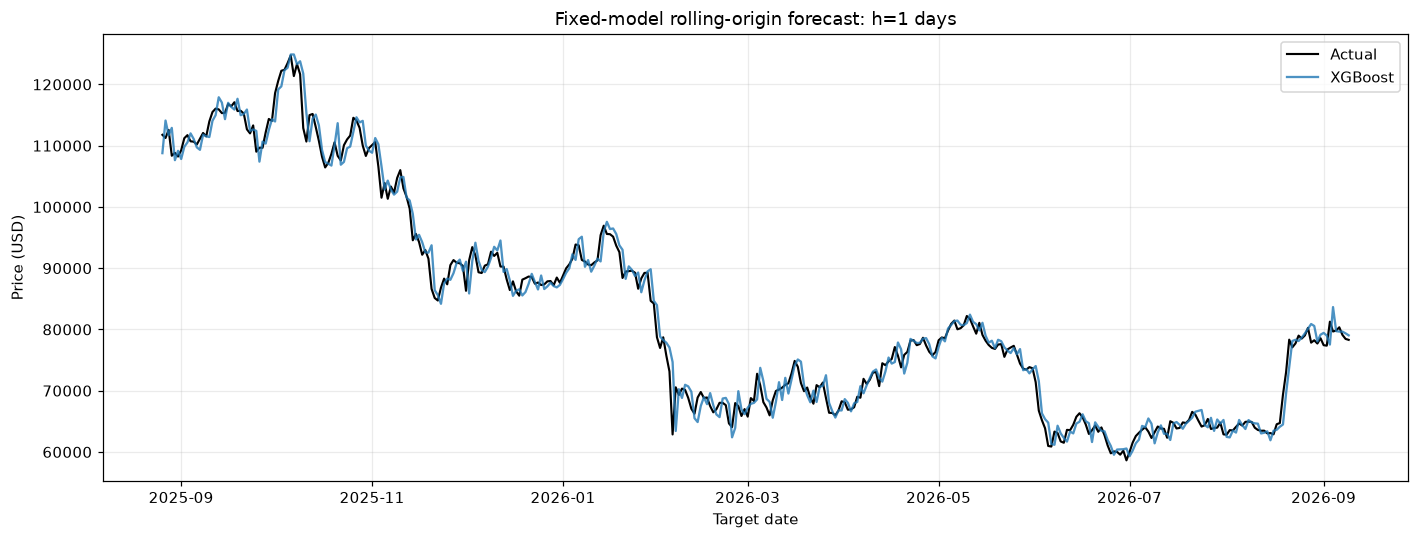

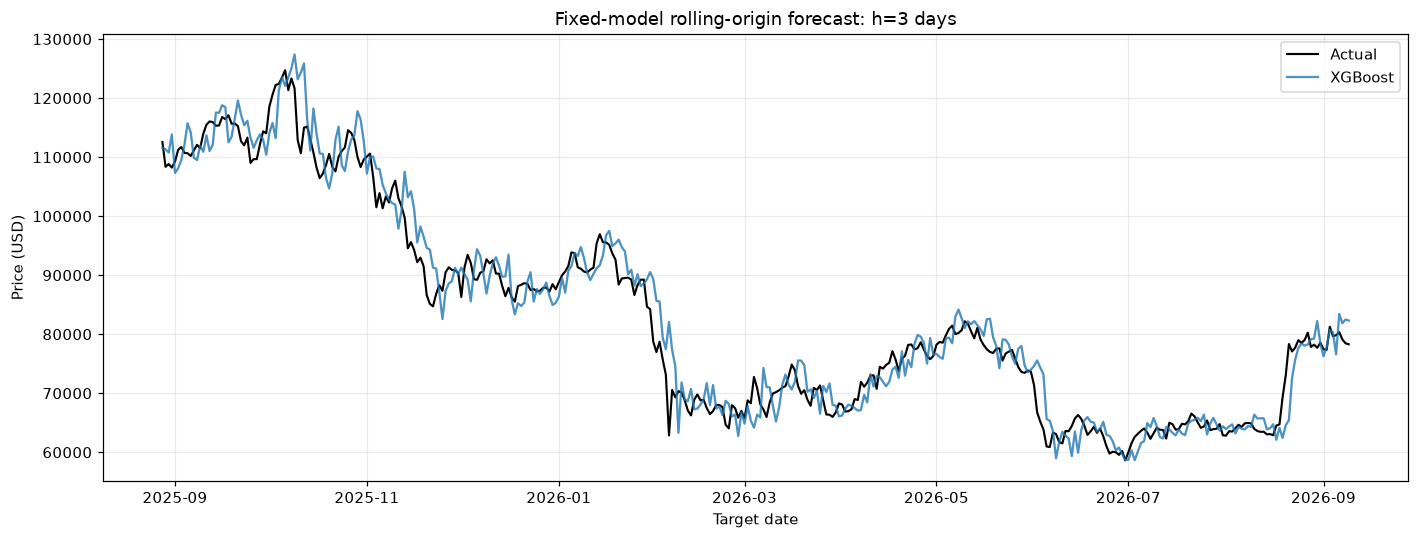

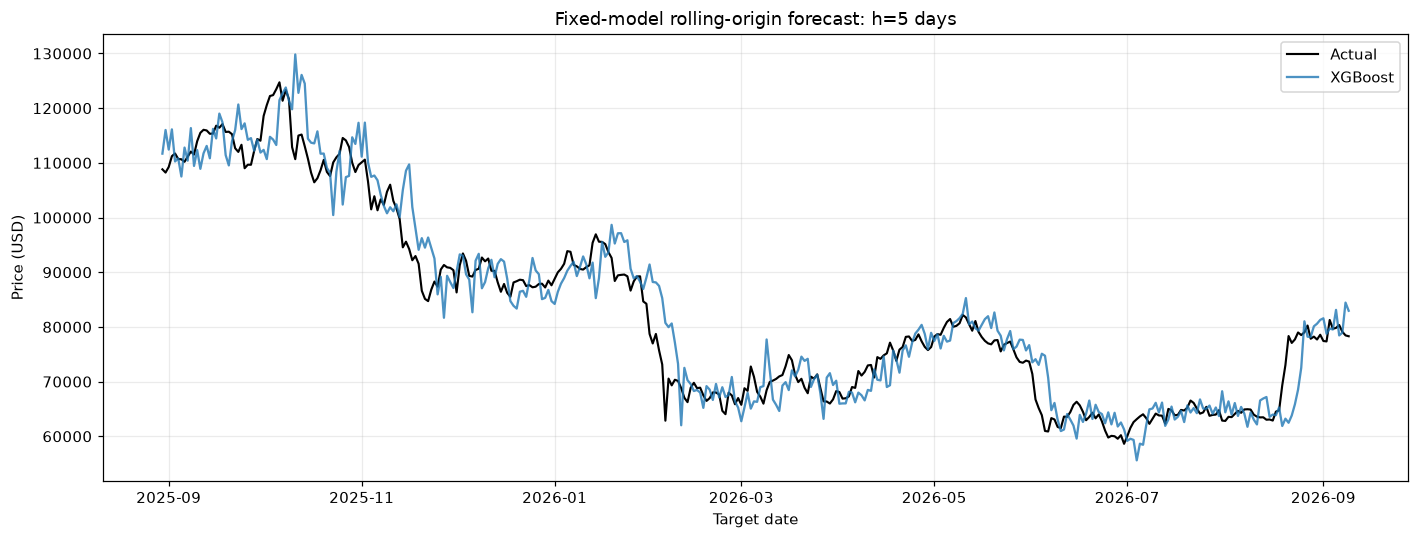

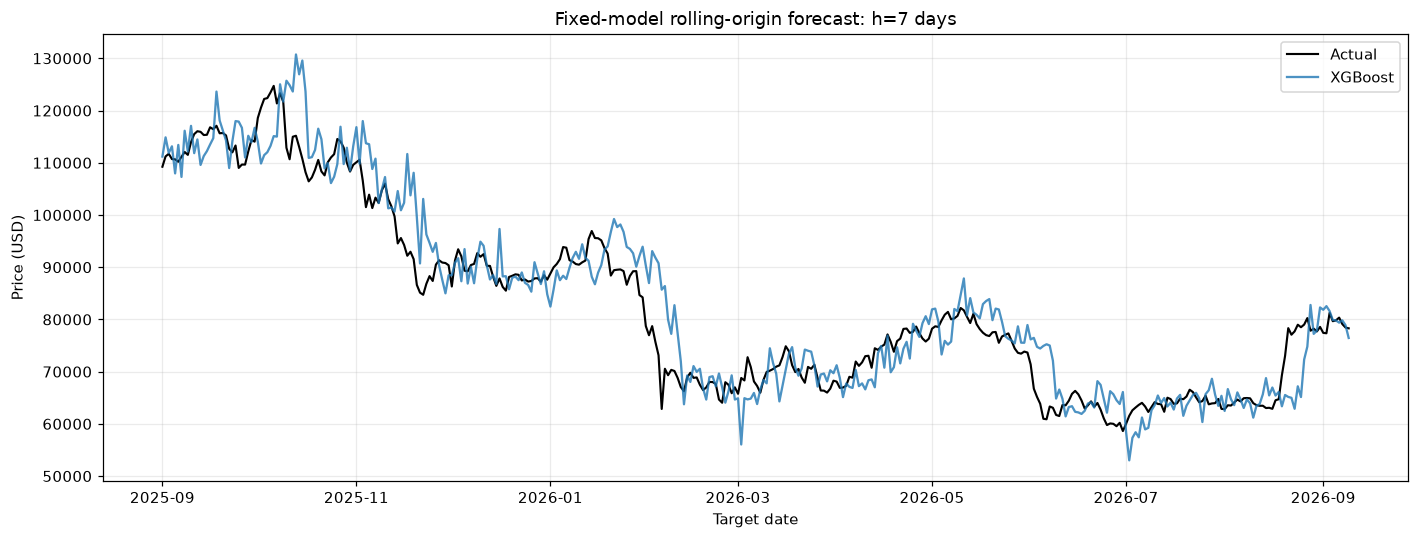

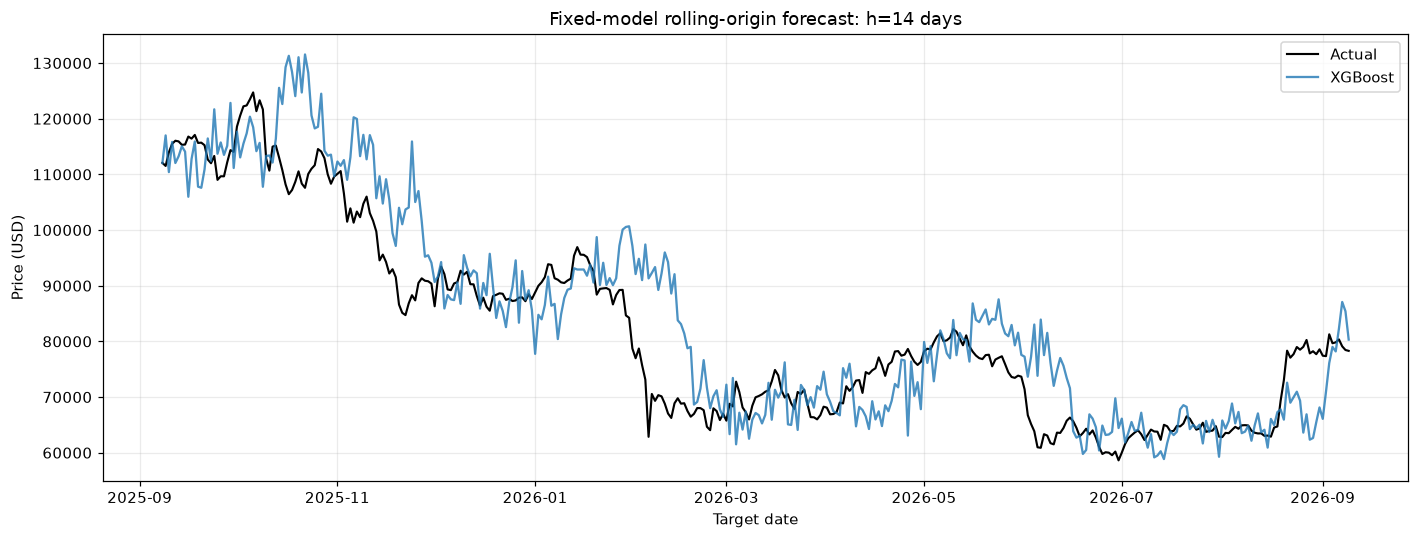

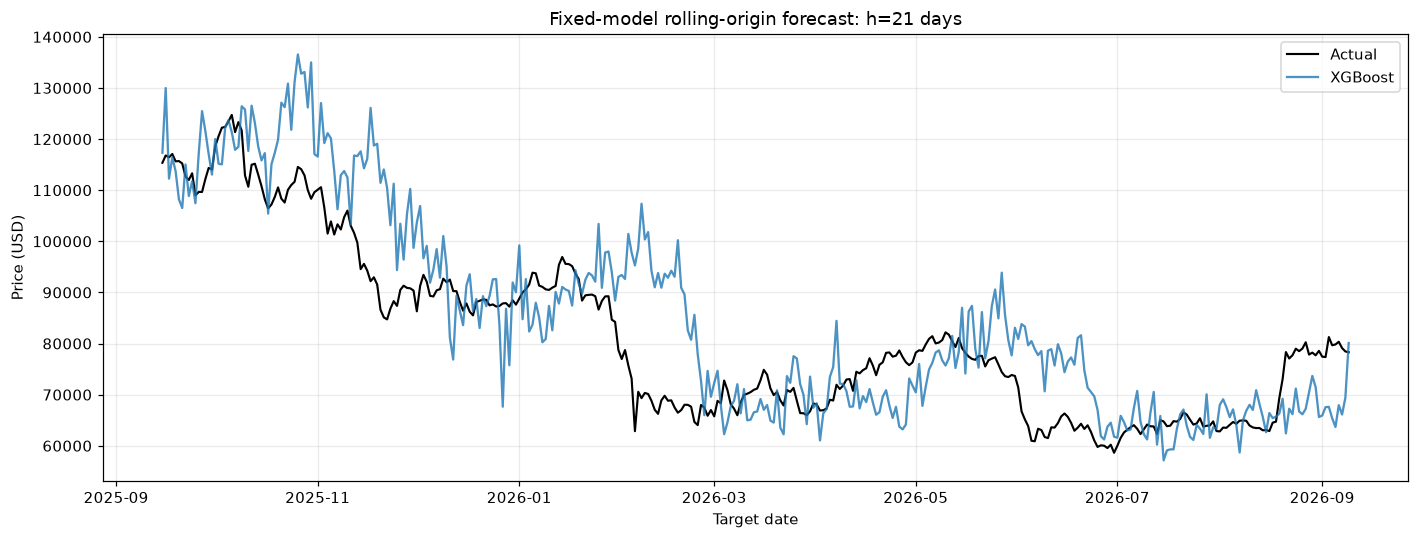

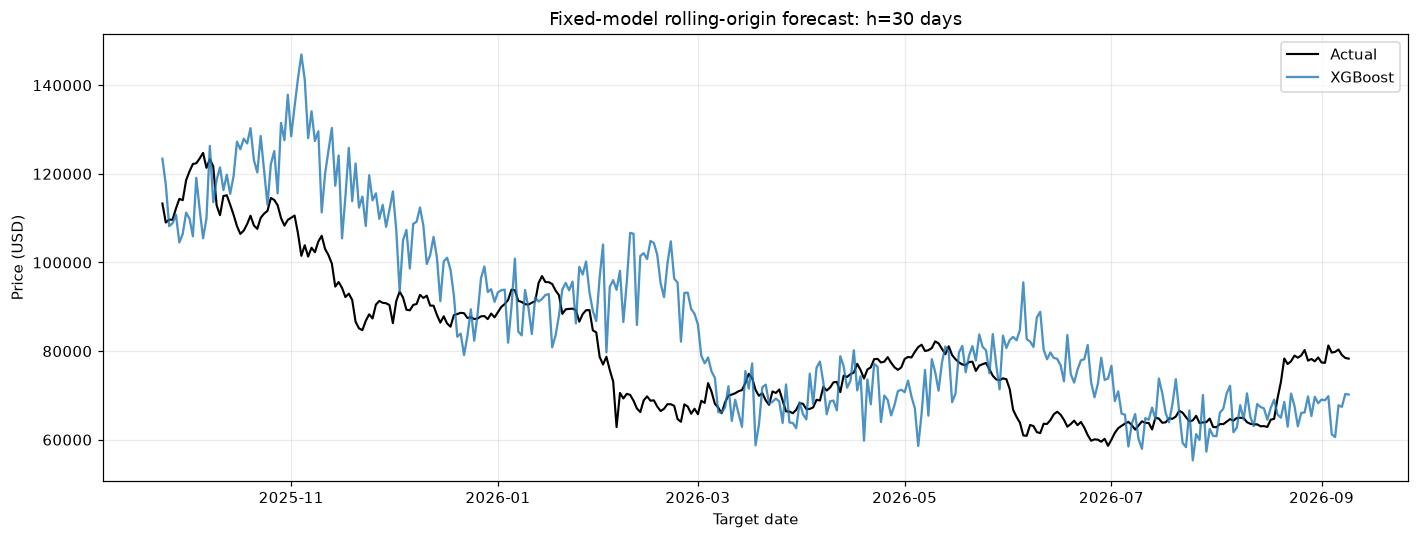

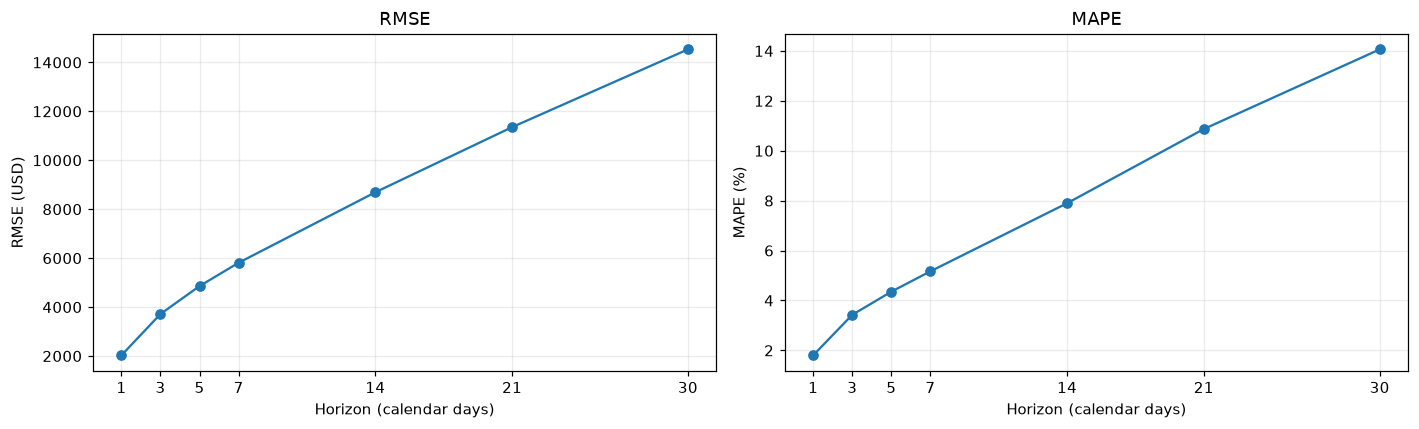

In [21]:
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)]
    fig,ax=plt.subplots(figsize=(13,5))
    ax.plot(group.target_date,group.actual,label='Actual',color='black',linewidth=1.4)
    ax.plot(group.target_date,group.xgb_fc,label='XGBoost',alpha=0.8)
    ax.set(title=f'Fixed-model rolling-origin forecast: h={h} days',xlabel='Target date',ylabel='Price (USD)')
    ax.legend(); save_figure(fig,f'07_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],['USD','%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=metric,xlabel='Horizon (calendar days)',ylabel=f'{metric} ({unit})',xticks=HORIZONS)
save_figure(fig,'08_error_vs_horizon.png')

## Step 10 Gain importance
Gain measures training split improvement, not causal influence or out-of-sample usefulness. Unused lags have zero gain. Raw gain values are shown; their magnitudes are not normalized across models with different target scales.

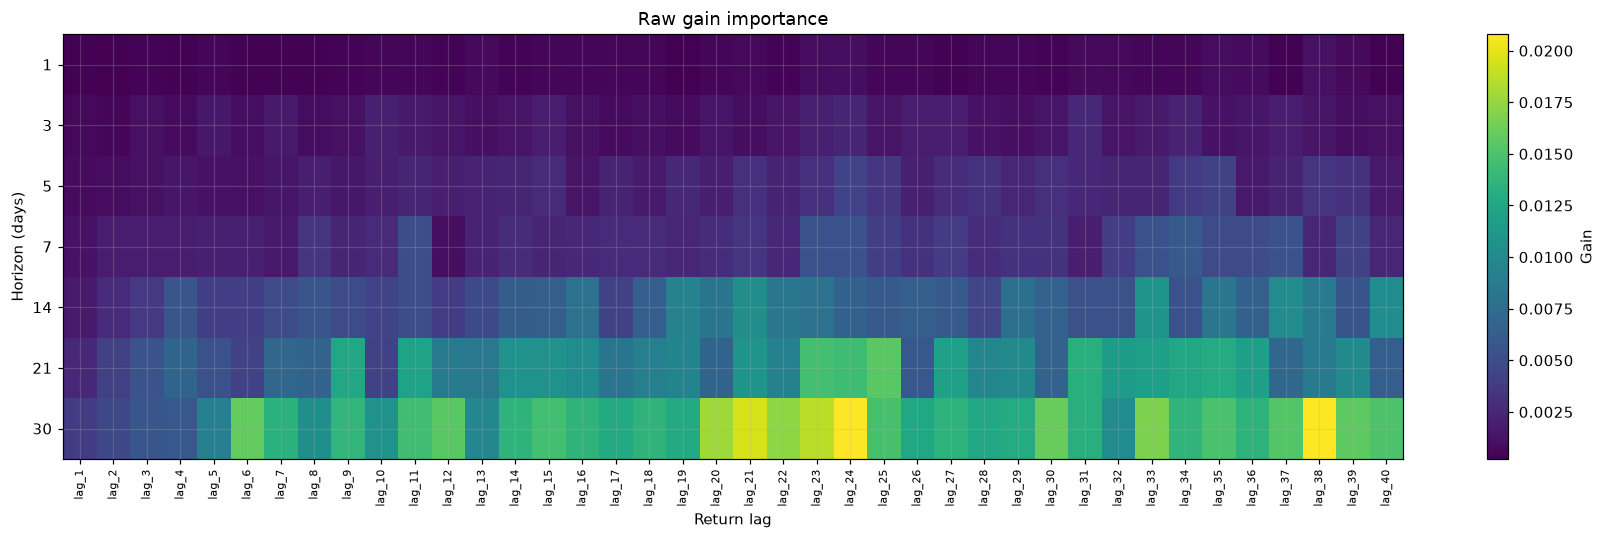

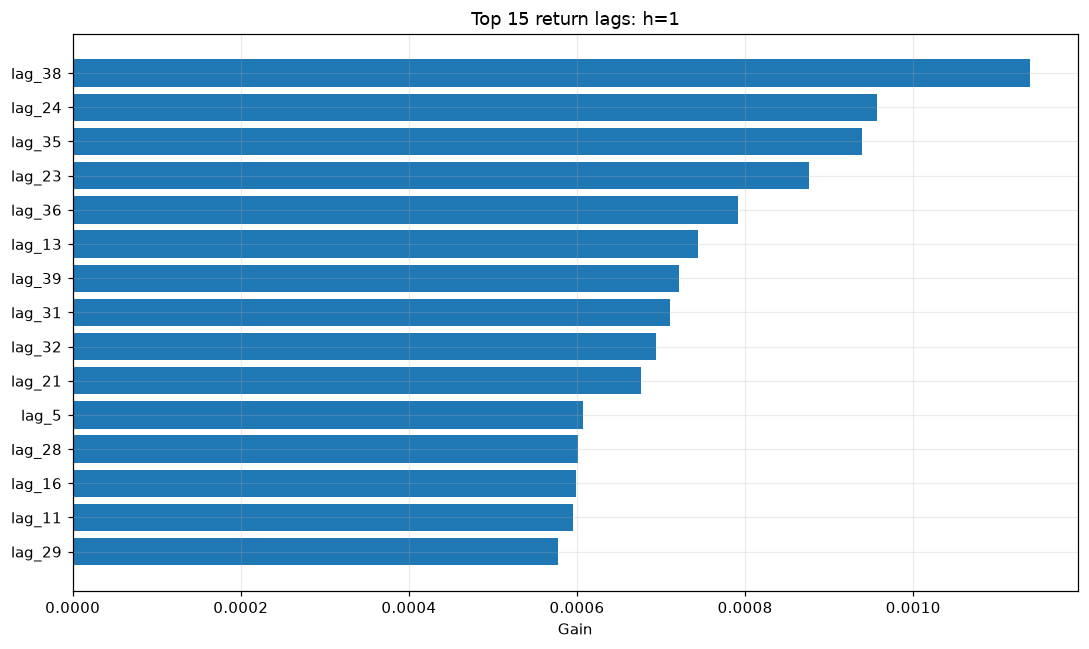

,h,feature,gain
0,1,lag_38,0.001139
1,3,lag_31,0.002561
2,5,lag_24,0.004337
3,7,lag_34,0.006012
4,14,lag_33,0.010874
5,21,lag_25,0.015505
6,30,lag_24,0.020799


In [22]:
importance_rows=[]
for h in HORIZONS:
    gain=models[h].get_booster().get_score(importance_type='gain')
    importance_rows.extend(dict(h=h,feature=f,gain=float(gain.get(f,0))) for f in feature_names)
feature_importance=pd.DataFrame(importance_rows)
save_table(feature_importance,'feature_importance.csv')
heat=feature_importance.pivot(index='h',columns='feature',values='gain').reindex(index=HORIZONS,columns=feature_names)
fig,ax=plt.subplots(figsize=(16,5))
im=ax.imshow(heat.to_numpy(),aspect='auto',cmap='viridis')
ax.set(yticks=np.arange(len(HORIZONS)),yticklabels=HORIZONS,
    xticks=np.arange(LOOKBACK),xticklabels=feature_names,xlabel='Return lag',ylabel='Horizon (days)',title='Raw gain importance')
ax.tick_params(axis='x',labelrotation=90,labelsize=7)
fig.colorbar(im,ax=ax,label='Gain')
save_figure(fig,'09_feature_importance_heatmap.png')
H1=next(h for h in HORIZONS if h==1)
top=feature_importance.loc[feature_importance.h.eq(H1)].nlargest(15,'gain').sort_values('gain')
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(top.feature,top.gain)
ax.set(title=f'Top 15 return lags: h={H1}',xlabel='Gain')
save_figure(fig,'10_feature_importance_h1.png')
top_by_horizon=feature_importance.loc[feature_importance.groupby('h').gain.idxmax()].reset_index(drop=True)
display(top_by_horizon)

### Step 10.1 - Lag ranking by Train Gain

**Ranking criterion:** descending XGBoost `gain`, separately for each forecast horizon from its fitted Train model. Gain is the average reduction in the training objective across splits using a feature. Rank 1 has the highest Gain; ties share a rank. Unused features have Gain = 0.

**Lag convention:** `lag_1` is the return observed at the forecast origin, `lag_2` is one day before the origin, and `lag_40` is 39 days before the origin. See `days_before_origin` for explicit timing.

Separate tables show the Top 10 lags for **h=1, 3, 5, 7, 14, 21, 30 calendar days**, in that order. `highest_gain` flags the highest positive Gain within each horizon. Compare raw Gain within a horizon; target scales differ across horizons. The complete ranking for every horizon is still exported to `lag_ranking_by_gain.csv`.

**Interpretation:** these are importance ranks after fitting. All 40 return features remain available to the model. This does not select a subset, establish LOOKBACK=40 as optimal, or prove causality or out-of-sample usefulness. No Test scores enter the ranking.


In [23]:
# Rank all return lags from the existing Train-fitted feature importance.
lag_ranking = feature_importance[['h', 'feature', 'gain']].copy()
lag_ranking['days_before_origin'] = lag_ranking['feature'].str.extract(r'lag_(\d+)', expand=False).astype(int) - 1
lag_ranking['rank'] = lag_ranking.groupby('h')['gain'].rank(method='min', ascending=False).astype(int)
lag_ranking['highest_gain'] = lag_ranking['rank'].eq(1) & lag_ranking['gain'].gt(0)
lag_ranking = lag_ranking.sort_values(
    ['h', 'rank', 'days_before_origin'], kind='stable'
)[['h', 'rank', 'feature', 'days_before_origin', 'gain', 'highest_gain']].reset_index(drop=True)
assert lag_ranking.groupby('h').size().eq(LOOKBACK).all()
assert not lag_ranking.duplicated(['h', 'feature']).any()
assert np.isfinite(lag_ranking['gain']).all() and lag_ranking['gain'].ge(0).all()
save_table(lag_ranking, 'lag_ranking_by_gain.csv')

# Show one Top 10 table per forecast horizon.
for horizon in HORIZONS:
    horizon_ranking = lag_ranking.loc[lag_ranking['h'].eq(horizon)]
    display(Markdown(f'**Top 10 lags for h={horizon} calendar day(s), ranked by Train Gain**'))
    display(horizon_ranking.head(10).style.format({'gain': '{:.9f}'}).hide(axis='index'))


**Top 10 lags for h=1 calendar day(s), ranked by Train Gain**

h,rank,feature,days_before_origin,gain,highest_gain
1,1,lag_38,37,0.001139098,True
1,2,lag_24,23,0.000957119,False
1,3,lag_35,34,0.000939541,False
1,4,lag_23,22,0.000876418,False
1,5,lag_36,35,0.000791070,False
1,6,lag_13,12,0.000743853,False
1,7,lag_39,38,0.000721742,False
1,8,lag_31,30,0.000710742,False
1,9,lag_32,31,0.000694054,False
1,10,lag_21,20,0.000676193,False


**Top 10 lags for h=3 calendar day(s), ranked by Train Gain**

h,rank,feature,days_before_origin,gain,highest_gain
3,1,lag_31,30,0.002560591,True
3,2,lag_24,23,0.002352121,False
3,3,lag_34,33,0.002312569,False
3,4,lag_23,22,0.002057359,False
3,5,lag_10,9,0.002054421,False
3,6,lag_26,25,0.001873897,False
3,7,lag_15,14,0.001794252,False
3,8,lag_37,36,0.001759656,False
3,9,lag_27,26,0.001754552,False
3,10,lag_33,32,0.001743771,False


**Top 10 lags for h=5 calendar day(s), ranked by Train Gain**

h,rank,feature,days_before_origin,gain,highest_gain
5,1,lag_24,23,0.004337283,True
5,2,lag_35,34,0.004262826,False
5,3,lag_34,33,0.003706036,False
5,4,lag_25,24,0.003517039,False
5,5,lag_38,37,0.003317931,False
5,6,lag_28,27,0.003247425,False
5,7,lag_39,38,0.003134299,False
5,8,lag_23,22,0.003074523,False
5,9,lag_30,29,0.002990893,False
5,10,lag_21,20,0.002984297,False


... (4 outputs left out)

**Top 10 lags for h=21 calendar day(s), ranked by Train Gain**

h,rank,feature,days_before_origin,gain,highest_gain
21,1,lag_25,24,0.015504927,True
21,2,lag_23,22,0.014680458,False
21,3,lag_24,23,0.014381627,False
21,4,lag_31,30,0.013124699,False
21,5,lag_35,34,0.012845819,False
21,6,lag_34,33,0.012533654,False
21,7,lag_9,8,0.012444342,False
21,8,lag_11,10,0.012166835,False
21,9,lag_27,26,0.011984071,False
21,10,lag_36,35,0.011876288,False


**Top 10 lags for h=30 calendar day(s), ranked by Train Gain**

h,rank,feature,days_before_origin,gain,highest_gain
30,1,lag_24,23,0.020798882,True
30,2,lag_38,37,0.020736681,False
30,3,lag_21,20,0.019531215,False
30,4,lag_23,22,0.018664414,False
30,5,lag_20,19,0.017875196,False
30,6,lag_22,21,0.017287223,False
30,7,lag_33,32,0.016740857,False
30,8,lag_30,29,0.015994685,False
30,9,lag_6,5,0.015835973,False
30,10,lag_39,38,0.015711365,False


## Step 11  Assumption and process checks
Group A chronology, leakage, past-only features, fixed trees and decreasing training curves are enforced. Train/Test return-scale comparability and target-range coverage are descriptive: no acceptable threshold was specified. Report out-of-range target proportions without changing parameters. Target range is not a mathematical prediction bound for boosted trees.

Group B reports h=1 Test log-return residual tests only; significant p-values do not trigger rejection, retuning or refitting. Higher-horizon targets overlap naturally.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,h,train_min,train_max,test_min,test_max,test_outside_train_fraction
0,1,-0.169947,0.136196,-0.151458,0.115526,0.000000
1,3,-0.275034,0.188751,-0.225028,0.190936,0.002646
2,5,-0.331631,0.219438,-0.225103,0.219692,0.002660
3,7,-0.402781,0.306707,-0.297850,0.217324,0.000000
4,14,-0.452936,0.329579,-0.353591,0.234516,0.000000
5,21,-0.433106,0.462758,-0.419140,0.247125,0.000000
6,30,-0.467614,0.462139,-0.399641,0.237416,0.000000


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Train features/targets exclude Test: h=1,1516.000000,NaN,PASS,
2,A,Features use only past: h=1,1.000000,NaN,PASS,
3,A,Trees fixed during inference: h=1,1.000000,NaN,PASS,
4,A,Training RMSE decreases: h=1,0.000548,NaN,PASS,"First=0.0261263, final=0.000547511; floating t..."
5,A,Target range coverage: h=1,0.000000,NaN,REPORTED,"Train [-0.169947,0.136196]; Test [-0.151458,0...."
6,A,Train features/targets exclude Test: h=3,1516.000000,NaN,PASS,
7,A,Features use only past: h=3,1.000000,NaN,PASS,
8,A,Trees fixed during inference: h=3,1.000000,NaN,PASS,
9,A,Training RMSE decreases: h=3,0.000568,NaN,PASS,"First=0.0434034, final=0.000567829; floating t..."


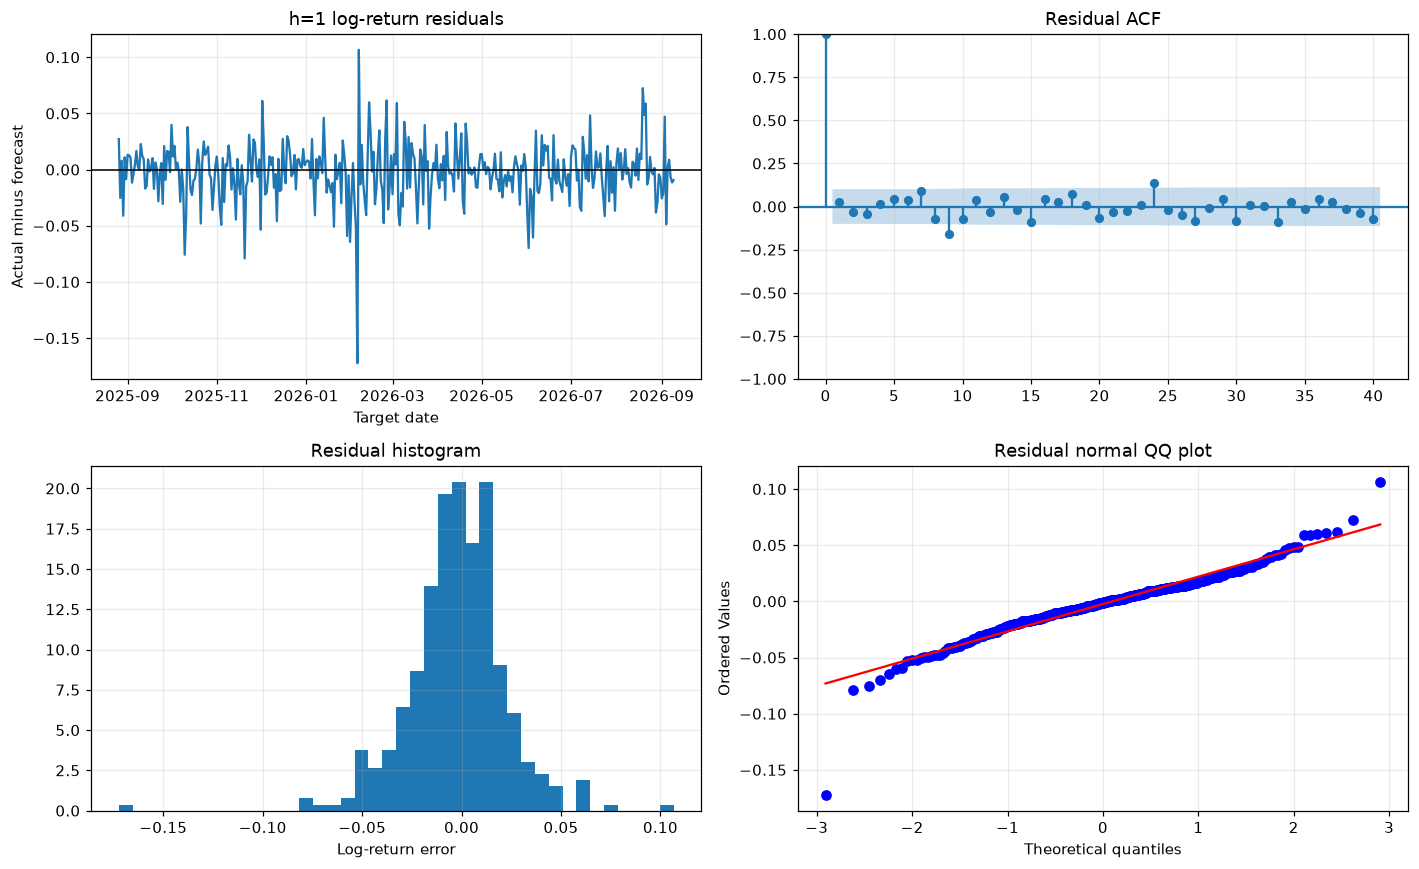

In [24]:
checks=[]
def check(group,name,statistic=np.nan,p_value=np.nan,status='PASS',note=''):
    checks.append(dict(group=group,check=name,statistic=statistic,p_value=p_value,**{'pass/fail':status},note=note))
assert df.index.is_monotonic_increasing and df.index.is_unique
check('A','Chronological unique dates',1)
range_rows=[]
for h in HORIZONS:
    batch=training[h]
    assert batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    assert (batch['input_idx']<=batch['origins'][:,None]).all()
    check('A',f'Train features/targets exclude Test: h={h}',int(batch['target_idx'].max()))
    check('A',f'Features use only past: h={h}',1)
    assert model_digest(models[h])==frozen_hashes[h]
    check('A',f'Trees fixed during inference: h={h}',1)
    curve=training_curve.loc[training_curve.h.eq(h),'train_rmse'].to_numpy()
    decreasing=bool((np.diff(curve)<=1e-10).all() and curve[-1]<curve[0])
    check('A',f'Training RMSE decreases: h={h}',float(curve[-1]),status='PASS' if decreasing else 'FAIL',
        note=f'First={curve[0]:.6g}, final={curve[-1]:.6g}; floating tolerance=1e-10')
    group=forecasts.loc[forecasts.h.eq(h)]
    actual_returns=np.log(group.actual.to_numpy()/group.price_origin.to_numpy())
    lo,hi=float(batch['y'].min()),float(batch['y'].max())
    fraction=float(((actual_returns<lo)|(actual_returns>hi)).mean())
    range_rows.append(dict(h=h,train_min=lo,train_max=hi,test_min=float(actual_returns.min()),
        test_max=float(actual_returns.max()),test_outside_train_fraction=fraction))
    check('A',f'Target range coverage: h={h}',fraction,status='REPORTED',
        note=f'Train [{lo:.6g},{hi:.6g}]; Test [{actual_returns.min():.6g},{actual_returns.max():.6g}]; statistic=outside fraction; no threshold specified')
range_summary=pd.DataFrame(range_rows)
save_table(range_summary,'target_range_summary.csv')
tr,te=log_ret.iloc[1:n_train],log_ret.iloc[n_train:]
check('A','Train/Test return mean and SD',float(te.std()/tr.std()),status='REPORTED',
    note=f'Train mean={tr.mean():.6g}, SD={tr.std():.6g}; Test mean={te.mean():.6g}, SD={te.std():.6g}; statistic=SD ratio; no threshold specified')
group=forecasts.loc[forecasts.h.eq(H1)]
e=pd.Series(np.log(group.actual.to_numpy()/group.price_origin.to_numpy())-predicted_returns[H1],index=pd.DatetimeIndex(group.target_date),name='residual')
assert len(e)==n_test and np.isfinite(e).all()
lb=acorr_ljungbox(e,lags=[10,20,30],return_df=True)
for lag,row in lb.iterrows():
    check('B',f'Ljung-Box lag {lag}',row.lb_stat,row.lb_pvalue,'PASS' if row.lb_pvalue>ALPHA else 'FAIL','Significance indicates residual autocorrelation; report only')
tstat,tp=stats.ttest_1samp(e,0)
check('B','Residual mean = 0',tstat,tp,'PASS' if tp>ALPHA else 'FAIL',f'Mean error={e.mean():.6g}; significance indicates bias')
arch,ap,_,_=het_arch(e,nlags=10)
check('B','ARCH LM (10 lags)',arch,ap,'PASS' if ap>ALPHA else 'FAIL','Significance indicates time-varying error variance')
jb,jp,skew,kurt=jarque_bera(e)
check('B','Jarque-Bera',jb,jp,'PASS' if jp>ALPHA else 'FAIL',f'Skew={skew:.6g}, kurtosis={kurt:.6g}; significance indicates non-normality')
assumption_checks=pd.DataFrame(checks)
save_table(assumption_checks,'assumption_checks.csv')
save_table(e.rename_axis('target_date').reset_index(),'residuals_h1.csv')
display(range_summary); display(assumption_checks)
assert not assumption_checks.loc[assumption_checks.group.eq('A'),'pass/fail'].eq('FAIL').any(), 'Process assumption failed; stop without retuning'
fig,axes=plt.subplots(2,2,figsize=(13,8))
axes[0,0].plot(e.index,e); axes[0,0].axhline(0,color='black',linewidth=1)
axes[0,0].set(title='h=1 log-return residuals',xlabel='Target date',ylabel='Actual minus forecast')
plot_acf(e,lags=40,ax=axes[0,1]); axes[0,1].set_title('Residual ACF')
axes[1,0].hist(e,bins=40,density=True); axes[1,0].set(title='Residual histogram',xlabel='Log-return error')
stats.probplot(e,dist='norm',plot=axes[1,1]); axes[1,1].set_title('Residual normal QQ plot')
save_figure(fig,'11_residual_diagnostics.png')

## Step 12 ? Execution summary
The following cell generates a Markdown report from the actual results. Rerunning updates displayed results and the report file. Test findings are reported without revising the predetermined design.

In [25]:
lines=['### XGBoost results from this execution','',
    f'Lookback={LOOKBACK}; direct strategy with {len(HORIZONS)} Train-fitted models; cumulative log-return target.',
    f'Chronological Train/Test={n_train}/{n_test}. No validation, tuning or early stopping.',
    'Reference parameters for the Train-only candidate grid (selected point-model parameters are reported in the Top 5 and best-model tables):',
    '```json',json.dumps(XGB_PARAMS,indent=2),'```',
    'No scaling. Tree responses are piecewise constant; cumulative returns anchored to origin prices avoid direct price-level trend extrapolation. Boosted tree outputs are not strictly bounded by Train target min/max.',
    '', '**Assumption checks**']
for row in assumption_checks.to_dict('records'):
    ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
    lines.append(f'- Group {row["group"]}, {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Test performance**','', '| h (days) | n | RMSE (USD) | MAPE (%) |','|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
for metric in ['RMSE','MAPE']:
    trend='increases at every adjacent requested horizon' if (np.diff(evaluation[metric])>0).all() else 'does not increase at every adjacent requested horizon'
    lines.append(f'- {metric} {trend}. Different horizons have different sample counts and overlapping targets.')
lines += ['', '**Most important training lag by gain**']
for row in top_by_horizon.itertuples(index=False): lines.append(f'- h={row.h}: {row.feature}, gain={row.gain:.6g}.')
lines += ['', '**Future forecasts from the latest observed date**']
for row in future_forecasts.itertuples(index=False): lines.append(f'- h={row.h}: origin={row.origin_date.date()}, target={row.target_date.date()}, forecast={row.xgb_fc:,.2f} USD.')
lines += ['', '**Limitations**',
    '- Hyperparameters are ranked by in-sample Train price RMSE over the declared grid; no validation/CV or Test-based selection. This does not establish best performance on new data.',
    '- Univariate returns only: no technical indicators, news, macroeconomic conditions or unexpected events.',
    f'- Test prices span {df.Price.iloc[n_train:].min():,.0f}?{df.Price.iloc[n_train:].max():,.0f} USD. Regime change is a potential limitation; this range is descriptive, not a formal break test.',
    '- No refitting during Test. Historical observations update inputs only.',
    '- Training RMSE and training gain are optimistic; there is no independent validation estimate.',
    '- MAPE is percentage error, not a statistical accuracy score. No calibrated prediction intervals are supplied.',
    '- Target-range and return-scale comparisons have no supplied acceptance thresholds and are reported descriptively. Residual tests are reporting only.']
lines += ['', '**XGBoost prediction intervals**', 'xgb_lo95/xgb_hi95: nominal central 95% Train-only quantile intervals; no Test calibration or tuning. Fixed quantile rearrangement is audited. Empirical Test coverage is reported separately; 95% coverage is not guaranteed.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
(SUMMARY_DIR/'summary.md').write_text(summary_markdown,encoding='utf-8')
required_figures=['01_raw_price_volume.png','02_log_return.png','03_return_distribution.png','04_acf_log_return.png',
    '05_train_test_split.png','06_training_curve.png',*[f'07_forecast_h{h}.png' for h in HORIZONS],
    '08_error_vs_horizon.png','09_feature_importance_heatmap.png','10_feature_importance_h1.png','11_residual_diagnostics.png']
required_tables=['split_summary.csv','training_curve.csv','fit_summary.csv','forecasts_long.csv',
    'evaluation_by_horizon.csv','feature_importance.csv','assumption_checks.csv',
    'future_forecast_by_horizon.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_tables += [f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]
assert all((TABLE_DIR/name).is_file() for name in required_tables)
assert all((FIGURE_DIR/name).is_file() for name in required_figures)
assert all((MODEL_DIR/f'xgb_h{h}.json').is_file() and model_digest(models[h])==frozen_hashes[h] for h in HORIZONS)
print('Completed: requested outputs saved; all fitted trees stayed fixed.')
display(Markdown('**Current experiment:** Top 5 point models ranked by Train price RMSE; Best on Train selected before Test. Previously inspected Test/future dates are retrospective evaluation. Separate quantile PI models keep their original fixed Train-only settings.'))


### XGBoost results from this execution

Lookback=40; direct strategy with 7 Train-fitted models; cumulative log-return target.
Chronological Train/Test=1517/380. No validation, tuning or early stopping.
Reference parameters for the Train-only candidate grid (selected point-model parameters are reported in the Top 5 and best-model tables):
```json
{
  "objective": "reg:squarederror",
  "n_estimators": 100,
  "learning_rate": 0.3,
  "max_depth": 6,
  "min_child_weight": 1,
  "gamma": 0,
  "subsample": 1.0,
  "colsample_bytree": 1.0,
  "reg_lambda": 1.0,
  "reg_alpha": 0.0,
  "tree_method": "hist",
  "random_state": 0
}
```
No scaling. Tree responses are piecewise constant; cumulative returns anchored to origin prices avoid direct price-level trend extrapolation. Boosted tree outputs are not strictly bounded by Train target min/max.

**Assumption checks**
- Group A, Chronological unique dates: PASS. 
- Group A, Train features/targets exclude Test: h=1: PASS. 
- Group A, Features use only past: h=1: PASS. 
- Group A, Trees fixed during inference: h=1: PASS. 
- Group A, Training RMSE decreases: h=1: PASS. First=0.0261263, final=0.000547511; floating tolerance=1e-10
- Group A, Target range coverage: h=1: REPORTED. Train [-0.169947,0.136196]; Test [-0.151458,0.115526]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=3: PASS. 
- Group A, Features use only past: h=3: PASS. 
- Group A, Trees fixed during inference: h=3: PASS. 
- Group A, Training RMSE decreases: h=3: PASS. First=0.0434034, final=0.000567829; floating tolerance=1e-10
- Group A, Target range coverage: h=3: REPORTED. Train [-0.275034,0.188751]; Test [-0.225028,0.190936]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=5: PASS. 
- Group A, Features use only past: h=5: PASS. 
- Group A, Trees fixed during inference: h=5: PASS. 
- Group A, Training RMSE decreases: h=5: PASS. First=0.0589648, final=0.000843389; floating tolerance=1e-10
- Group A, Target range coverage: h=5: REPORTED. Train [-0.331631,0.219438]; Test [-0.225103,0.219692]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=7: PASS. 
- Group A, Features use only past: h=7: PASS. 
- Group A, Trees fixed during inference: h=7: PASS. 
- Group A, Training RMSE decreases: h=7: PASS. First=0.0685356, final=0.00109195; floating tolerance=1e-10
- Group A, Target range coverage: h=7: REPORTED. Train [-0.402781,0.306707]; Test [-0.29785,0.217324]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=14: PASS. 
- Group A, Features use only past: h=14: PASS. 
- Group A, Trees fixed during inference: h=14: PASS. 
- Group A, Training RMSE decreases: h=14: PASS. First=0.0960625, final=0.00163273; floating tolerance=1e-10
- Group A, Target range coverage: h=14: REPORTED. Train [-0.452936,0.329579]; Test [-0.353591,0.234516]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=21: PASS. 
- Group A, Features use only past: h=21: PASS. 
- Group A, Trees fixed during inference: h=21: PASS. 
- Group A, Training RMSE decreases: h=21: PASS. First=0.120255, final=0.00145428; floating tolerance=1e-10
- Group A, Target range coverage: h=21: REPORTED. Train [-0.433106,0.462758]; Test [-0.41914,0.247125]; statistic=outside fraction; no threshold specified
- Group A, Train features/targets exclude Test: h=30: PASS. 
- Group A, Features use only past: h=30: PASS. 
- Group A, Trees fixed during inference: h=30: PASS. 
- Group A, Training RMSE decreases: h=30: PASS. First=0.14206, final=0.00174247; floating tolerance=1e-10
- Group A, Target range coverage: h=30: REPORTED. Train [-0.467614,0.462139]; Test [-0.399641,0.237416]; statistic=outside fraction; no threshold specified
- Group A, Train/Test return mean and SD: REPORTED. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077; statistic=SD ratio; no threshold specified
- Group B, Ljung-Box lag 10: FAIL, p=0.0319182. Significance indicates residual autocorrelation; report only
- Group B, Ljung-Box lag 20: PASS, p=0.065754. Significance indicates residual autocorrelation; report only
- Group B, Ljung-Box lag 30: FAIL, p=0.0261388. Significance indicates residual autocorrelation; report only
- Group B, Residual mean = 0: PASS, p=0.0650612. Mean error=-0.00237623; significance indicates bias
- Group B, ARCH LM (10 lags): FAIL, p=1.01899e-06. Significance indicates time-varying error variance
- Group B, Jarque-Bera: FAIL, p=2.49652e-143. Skew=-0.7014, kurtosis=9.28558; significance indicates non-normality

**Test performance**

| h (days) | n | RMSE (USD) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 380 | 2,027.97 | 1.80 |
| 3 | 378 | 3,716.56 | 3.42 |
| 5 | 376 | 4,859.02 | 4.35 |
| 7 | 374 | 5,811.37 | 5.17 |
| 14 | 367 | 8,692.33 | 7.90 |
| 21 | 360 | 11,353.84 | 10.87 |
| 30 | 351 | 14,530.76 | 14.06 |
- RMSE increases at every adjacent requested horizon. Different horizons have different sample counts and overlapping targets.
- MAPE increases at every adjacent requested horizon. Different horizons have different sample counts and overlapping targets.

**Most important training lag by gain**
- h=1: lag_38, gain=0.0011391.
- h=3: lag_31, gain=0.00256059.
- h=5: lag_24, gain=0.00433728.
- h=7: lag_34, gain=0.00601236.
- h=14: lag_33, gain=0.0108745.
- h=21: lag_25, gain=0.0155049.
- h=30: lag_24, gain=0.0207989.

**Future forecasts from the latest observed date**
- h=1: origin=2026-09-09, target=2026-09-10, forecast=78,676.42 USD.
- h=3: origin=2026-09-09, target=2026-09-12, forecast=78,888.22 USD.
- h=5: origin=2026-09-09, target=2026-09-14, forecast=78,577.47 USD.
- h=7: origin=2026-09-09, target=2026-09-16, forecast=81,319.36 USD.
- h=14: origin=2026-09-09, target=2026-09-23, forecast=84,126.54 USD.
- h=21: origin=2026-09-09, target=2026-09-30, forecast=86,290.35 USD.
- h=30: origin=2026-09-09, target=2026-10-09, forecast=81,558.33 USD.

**Limitations**
- Hyperparameters are ranked by in-sample Train price RMSE over the declared grid; no validation/CV or Test-based selection. This does not establish best performance on new data.
- Univariate returns only: no technical indicators, news, macroeconomic conditions or unexpected events.
- Test prices span 58,631?124,725 USD. Regime change is a potential limitation; this range is descriptive, not a formal break test.
- No refitting during Test. Historical observations update inputs only.
- Training RMSE and training gain are optimistic; there is no independent validation estimate.
- MAPE is percentage error, not a statistical accuracy score. No calibrated prediction intervals are supplied.
- Target-range and return-scale comparisons have no supplied acceptance thresholds and are reported descriptively. Residual tests are reporting only.

**XGBoost prediction intervals**
xgb_lo95/xgb_hi95: nominal central 95% Train-only quantile intervals; no Test calibration or tuning. Fixed quantile rearrangement is audited. Empirical Test coverage is reported separately; 95% coverage is not guaranteed.

Completed: requested outputs saved; all fitted trees stayed fixed.


**Current experiment:** Top 5 point models ranked by Train price RMSE; Best on Train selected before Test. Previously inspected Test/future dates are retrospective evaluation. Separate quantile PI models keep their original fixed Train-only settings.

### Current experiment summary

The generated summary above reports the current Train-ranked XGBoost execution; earlier fixed-parameter numerical summaries are superseded.

## References (2023?2026)
Research context only; the notebook follows the user's fixed protocol rather than reproducing these studies' tuning, indicators or validation schemes.

1. Hafid et al. (2024). [Cryptocurrency Price Forecasting Using XGBoost Regressor and Technical Indicators](https://arxiv.org/abs/2407.11786). Context: cryptocurrency forecasting with indicators; this notebook uses returns only.
2. Radmand, Pirgazi & Sorkhi (2025). [A Hybrid TLBO?XGBoost Model With Novel Labeling for Bitcoin Price Prediction](https://doi.org/10.1155/INT/6674437). Context: optimized hybrid design; no optimizer is used here.
3. (2025). [Empirical Calibration of XGBoost Model Hyperparameters Using the Bayesian Optimisation Method: The Case of Bitcoin Volatility](https://doi.org/10.3390/jrfm18090487). *Journal of Risk and Financial Management*, 18(9), 487. Context: tuned volatility forecasting, a different target.
4. Malla et al. (2026). [XGBoost Forecasting of NEPSE Index Log Returns with Walk Forward Validation](https://arxiv.org/abs/2601.08896). Context: return features; its tuning/refitting protocol is not used here.
5. (2023). [Improved Sales Forecasting using Trend and Seasonality Decomposition with LightGBM](https://arxiv.org/abs/2305.17201). Context: tree forecasting and trend extrapolation in sales; not a Bitcoin result or a strict bound on boosted predictions.

Implementation documentation: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), [Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html). Values in `XGB_PARAMS` are explicit specification choices; library defaults can differ by version.